## Markowitz Modern Portfolio Theory: Portfolio Backtesting


In [ ]:
#Risk free always = 0
#Annualization: Multiply by 252
#Missing values are being treated as forward filling (defender contra abordagens estilo interpolação linear que está a olhar para a frente para calcular um valor intermédio (o que pode criar falsos retornos)).
#Atenção pois o forward fill também tem defeitos como mitigar ou fazer diminuir a volatilidade dos retornos.

#Survivorship bias ????

# -------------------------------------------------------------------------------------------
# Importing Packages
# -------------------------------------------------------------------------------------------
import numpy as np
import pandas as pd
import yfinance as yf
from scipy.optimize import minimize
import quantstats as qs
from datetime import datetime
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib import colormaps
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
import os
#Package for the Risk Parity-Equal Risk Contribution Portfolio
#The package utilized makes use of specifically designed algorithms for this type of problems, therefore optimizing the convergence algorithm
import riskparityportfolio as rp
#Package of performance metrics
import quantstats as qs


#Loading bar
from tqdm import tqdm

file_path = r"" # <- Add the path to your folder here

c:\Users\user\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\riskparityportfolio\sca.py:10: UserWarning: not able to import quadprog. the successive convex optimizer wont work.
  warnings.warn(


## Loading Data

In [2]:
# -------------------------------------------------------------------------------------------
# Loading Data
# -------------------------------------------------------------------------------------------
symbols = [
    #Tech
    "AAPL", "MSFT", "ORCL", "AMZN", "INTC",
    #Healthcare
    "JNJ", "PFE", "MRK", "UNH", "ABT",
    #Financials
    "JPM", "BAC", "WFC", "GS", "AXP",
    #Consumer Staples
    "PG", "KO", "PEP", "WMT", "CL",
    #Commodities and Bonds
    "GC=F","SI=F","TLT",
    #Real Estate
    "VNQ",
    #Energy
     "XOM"
    ]

groups = {
    "Technology": ["AAPL", "MSFT", "ORCL", "AMZN", "INTC"],
    "Healthcare": ["JNJ", "PFE", "MRK", "UNH", "ABT"],
    "Financials": ["JPM", "BAC", "WFC", "GS", "AXP"],
    "Consumer Staples": ["PG", "KO", "PEP", "WMT", "CL"],
    "Commodities and Bonds": ["GC=F", "SI=F", "TLT"],
    "Real Estate": ["VNQ"],
    "Energy": ["XOM"],
}

prices = yf.download(symbols, start="2010-01-01", end="2025-01-01", auto_adjust=False, multi_level_index=False)

prices=prices["Adj Close"]

prices = prices.ffill(limit=2)
print("Number of missing entries after data forward filling: ",prices.isna().sum())
print(prices)

#Download an S&P500 ETF CSSPX
prices_SP500 = yf.download(
    "CSSPX.MI",
    start="2010-01-01",
    end="2025-01-01",
    auto_adjust=False,
    multi_level_index=False,
)["Adj Close"].ffill(limit=2)
print(prices_SP500)


[*********************100%***********************]  25 of 25 completed


Number of missing entries after data forward filling:  Ticker
AAPL    0
ABT     0
AMZN    0
AXP     0
BAC     0
CL      0
GC=F    0
GS      0
INTC    0
JNJ     0
JPM     0
KO      0
MRK     0
MSFT    0
ORCL    0
PEP     0
PFE     0
PG      0
SI=F    0
TLT     0
UNH     0
VNQ     0
WFC     0
WMT     0
XOM     0
dtype: int64
Ticker            AAPL         ABT        AMZN         AXP        BAC  \
Date                                                                    
2010-01-04    6.400960   17.968187    6.695000   32.192963  11.977129   
2010-01-05    6.412027   17.823013    6.734500   32.122173  12.366440   
2010-01-06    6.310035   17.921999    6.612500   32.641430  12.511475   
2010-01-07    6.298370   18.070473    6.500000   33.170811  12.923690   
2010-01-08    6.340244   18.162842    6.676000   33.147125  12.809181   
...                ...         ...         ...         ...        ...   
2024-12-24  256.339722  109.894524  229.050003  296.882904  42.690815   
2024-12-26  257.15

[*********************100%***********************]  1 of 1 completed

Date
2010-05-19     72.849998
2010-05-20     72.849998
2010-05-21     72.849998
2010-05-24     72.849998
2010-05-25     72.849998
                 ...    
2024-12-19    603.640015
2024-12-20    605.869995
2024-12-23    604.760010
2024-12-27    606.770020
2024-12-30    603.619995
Name: Adj Close, Length: 3717, dtype: float64


## 2 Compare the core portfolio strategies

**Portfolio Definitions**

In [3]:
# 1/N Portfolio
def Equal_Weight_Portfolio(dataset:pd.DataFrame) ->pd.Series:
    return pd.Series([1/dataset.shape[1] for asset in range(dataset.shape[1])], index=dataset.columns) 


# Quintile portfolio
def quintile_portfolio(dataset:pd.DataFrame) ->pd.Series:
    returns = dataset.pct_change().dropna()
    n_selected = max(1, dataset.shape[1] // 5)  #We will be choosing only 20% of the Portfolio, therefore we divide the total number of assets by 5 to get the number of assets to pick

    ranking = returns.mean().sort_values(ascending=False).index
    weights = np.zeros(dataset.shape[1])

    weights[[dataset.columns.get_loc(asset)
             for asset in ranking[:n_selected]]] = 1 / n_selected

    return pd.Series(weights, index=dataset.columns)

def gmvp_portfolio(dataset: pd.DataFrame) -> pd.Series:
    returns = dataset.pct_change().dropna()
    covariance = returns.cov().to_numpy()*252

    n_assets = len(dataset.columns)

    result = minimize(
        fun=lambda weights: weights @ covariance @ weights,
        x0=np.full(n_assets, 1 / n_assets),
        method="SLSQP",
        bounds=[(0, 1)] * n_assets,
        constraints={
            "type": "eq",
            "fun": lambda weights: weights.sum() - 1,
        },
    )

    if not result.success:
        raise RuntimeError(f"GMVP optimisation failed: {result.message}")

    return pd.Series(result.x, index=dataset.columns)


def markowitz_portfolio(
    prices: pd.DataFrame,
    risk_aversion: float = 0.5
) -> pd.Series:

    returns = prices.pct_change().dropna()
    mean_returns = returns.mean().to_numpy() * 252
    covariance = returns.cov().to_numpy() * 252
    n_assets = prices.shape[1]

    result = minimize(
        lambda weights: -(weights @ mean_returns - risk_aversion * weights @ covariance @ weights),
        x0=np.ones(n_assets) / n_assets,
        bounds=[(0, 1)] * n_assets,
        constraints={"type": "eq", "fun": lambda w: w.sum() - 1},
    )

    if not result.success:
        raise RuntimeError(
            f"Markowitz optimisation failed: {result.message}"
        )
    return pd.Series(result.x, index=prices.columns)

def max_sharpe_ratio_portfolio(dataset: pd.DataFrame, rf:float=0)->pd.Series:
    #Computation of returns and covariance matrix    
    returns = dataset.pct_change().dropna()
    covariance = returns.cov() * 252

    n_assets = len(returns.columns)

    #To have an initial point of weights
    initial_weights = np.repeat(
        1 / n_assets,
        n_assets
    )

    #To create a constraint where the sum of all weights must add to 1
    constraints = [
        {
        "type": "eq",
        "fun": lambda weights: np.sum(weights) - 1
        }
    ]

    #To create a list that is telling the finder that all points must be between 0 and 1, so no short selling
    bounds = [(0, 1) for _ in range(n_assets)]

    def sharpe_ratio(weights):
        return (np.sum(returns.mean()*weights)*252 - rf) / np.sqrt(weights @ covariance @ weights)


    #This function is to find the Portfolio with maximum sharpe ratio. Its extension .x will contain the solution vector. Here, as we are trying to find a maximum for the sharpe ratio, we are once more using the trick for
    # Maximise Sharpe ratio by minimising its negative value
    result = minimize(
        lambda weights: -1*sharpe_ratio(weights),
        initial_weights,
        method="SLSQP",
        bounds=bounds,
        constraints=constraints
    )

    if not result.success:
        raise RuntimeError(
            f"Maximum Sharpe optimisation failed: {result.message}"
        )
    
    return pd.Series(result.x, index=dataset.columns)  

def inverse_volatility_portfolio(dataset: pd.DataFrame) -> pd.Series:
    returns = dataset.pct_change().dropna()

    volatility = returns.std()

    inverse_volatility = 1 / volatility 
    weights = inverse_volatility / inverse_volatility.sum()

    return pd.Series(weights, index=dataset.columns)  

#This was the only Portfolio definition made with the usage of a package due to problems on the usual Python convergence algorithm
#The package utilized makes use of specifically designed algorithms for this type of problems, therefore optimizing the convergence algorithm
def risk_parity_portfolio(dataset: pd.DataFrame) -> pd.Series:
    returns = dataset.pct_change(fill_method=None).dropna()
    covariance = returns.cov().to_numpy()

    n_assets = covariance.shape[0]
    risk_budget = np.full(n_assets, 1 / n_assets)
    
    #By default the package does not allow shortselling 
    weights = rp.vanilla.design(covariance, risk_budget)

    return pd.Series(weights, index=dataset.columns, name="weight")

def most_diversified_portfolio(dataset: pd.DataFrame)->pd.Series:
    #Computation of returns and covariance matrix    
    returns = dataset.pct_change().dropna()
    covariance = returns.cov() * 252

    n_assets=len(dataset.columns)

    def objective(w):
        return -1*(w @ np.sqrt(np.diag(covariance)) / np.sqrt( w @ covariance @ w))

    # Restrições e limites
    constraints = [{"type": "eq", "fun": lambda w: np.sum(w) - 1}]
    bounds = [(0, 1.0)] * n_assets #No shortselling

    result = minimize(
        objective,
        x0=[1/n_assets for _ in range(n_assets)],
        method="SLSQP",
        bounds=bounds,
        constraints=constraints
    )

    if not result.success:
        raise RuntimeError(
            f"Most Diversified optimisation failed: {result.message}"
        )
    
    return pd.Series(result.x, index=dataset.columns)  


def maximum_decorrelation_portfolio(dataset: pd.DataFrame)->pd.Series:
    #Computation of returns and corerlation matrix    
    returns = dataset.pct_change().dropna()
    correlation = returns.corr().to_numpy(dtype=float)

    n_assets=len(dataset.columns)

    def objective(w):
        return w @ correlation @ w

    # Restrições e limites
    constraints = [{"type": "eq", "fun": lambda w: np.sum(w) - 1}]
    bounds = [(0, 1.0)] * n_assets #No shortselling

    result = minimize(
        objective,
        x0=[1/n_assets for _ in range(n_assets)],
        method="SLSQP",
        bounds=bounds,
        constraints=constraints,
        options={"ftol": 1e-10, "maxiter": 1000},
    )
    
    if not result.success:
        raise RuntimeError(f"A otimização falhou: {result.message}")

    return pd.Series(result.x,
        index=dataset.columns)

portfolios = {
    "1/N":Equal_Weight_Portfolio,
    "Quintile": quintile_portfolio,
    "GMVP": gmvp_portfolio,
    "Markowitz": markowitz_portfolio,
    "Max Sharpe Ratio":max_sharpe_ratio_portfolio,
    "Inverse Volatility Portfolio":inverse_volatility_portfolio,
    "Risk Parity Portfolio":risk_parity_portfolio,
    "Most Diversified Portfolio":most_diversified_portfolio,
    "Maximum Decorrelation Portfolio":maximum_decorrelation_portfolio
}



## Backtesting

**Generating 100 three-year datasets by randomly selecting contiguous historical periods and subsets of the
investment universe**
<br>
-Observations are kept in chronological order within each dataset
<br>
-Same sampled periods and asset subsets are being used for every strategy.
<br>
-Seed utilized was recorded as "SEED=1904"

In [4]:
#Let's randomly choose N datasets to use for backtesting
SEED = 1904
rng = np.random.default_rng(SEED)

datasets = {}

N=100 #100 Datasets 
Years=5 #Each has 5 years worth of data
assets=10 #Randomly choose a number of assets for each dataset
FEES=0.0015 #15 bps
rf=0 #Risk-free rate = 0 bps
for i in range(N):
    start = rng.integers(0, len(prices) - 252*Years)
    stocks = rng.choice(prices.columns, assets, replace=False) 
    datasets[f"dataset {i + 1}"] = prices.iloc[start:start + 252*Years][stocks]


**Backtesting Function**
<br>
-Only information available at each portfolio formation date is being used.
<br>
-Trades are being executed only after the information used to set the weights becomes available, so no future observations are being used to calibrate a strategy.
<br>
-Portfolio weights are being allowed to drift between rebalancing dates.

In [5]:
def backtest_with_drift(
    dataset: pd.DataFrame,
    strategy,
    rebalance_every: int = 63,
    lookback: int = 252*2,
    fee_per_trade: float = 0.0,   # ex.: 5 bps = 0.0005
    return_weights: bool = False,
    return_turnover: bool = False,
    ):

    returns = dataset.pct_change().dropna()
    portfolio_returns = []
    weights_history = {}
    turnover_history = {}

    #To start a register of previous weights. Will be helpfull to keep recording turnover
    previous_weights = pd.Series(0.0, index=dataset.columns)

    for start in range(lookback, len(returns), rebalance_every):
        #The end for our period will be the minimum between the end of our dataset and the start position + rebalancing period
        end = min(start + rebalance_every, len(returns))
        rebalance_date = returns.index[start]

        #We calibrate the weights at the beggining period by looking at the period between our start - lookback and our the start of our trading window
        weights = strategy(
            dataset.iloc[start - lookback:start]
        )

        if abs(weights.sum() - 1) > 1e-4:
            raise ValueError(f"Weights sum to {weights.sum()} for strategy {strategy}.")

        # Transaction cost proportional to portfolio turnover
        turnover = (weights - previous_weights).abs().sum()
        rebalancing_cost = turnover * fee_per_trade

        #Between our starting date and up until the next rebalancing period we will be having a portfolio whose weights will only be changed by the returns of the assets whitin the period
        for date, asset_returns in returns.iloc[start:end].iterrows():
            weights_history[date] = weights.copy()
            portfolio_return = weights @ asset_returns

            # Charge rebalancing cost on the first day of the period
            if date == rebalance_date:
                portfolio_return -= rebalancing_cost
                turnover_history[date] = turnover

            portfolio_returns.append(portfolio_return)

            # Drift weights with daily returns
            weights *= 1 + asset_returns
            weights /= weights.sum()

        #This serves to record the weights at the end of a trading window, in between rebalancings
        previous_weights = weights.copy()

    portfolio_returns = pd.Series(portfolio_returns, index=returns.index[lookback:])
    turnover_history = pd.Series(turnover_history, name="turnover")

    evaluation_years = (portfolio_returns.index[-1]- portfolio_returns.index[0]).days / 365 #Becarefull as subtracting dates here will give the difference in days, so we divide by 365 not 252 !
    annualised_one_way_turnover = (
        turnover_history.iloc[1:] / 2
    ).sum() / evaluation_years

    if return_weights and return_turnover:
        return (
            portfolio_returns,
            pd.DataFrame.from_dict(weights_history, orient="index"),
            (turnover_history, annualised_one_way_turnover)
        )

    elif return_weights:
        return portfolio_returns, pd.DataFrame.from_dict(weights_history, orient="index")

    elif return_turnover:
        return portfolio_returns, (
            turnover_history,
            annualised_one_way_turnover,
        )
    else:
        return portfolio_returns

#To store the results
results_rebalancing_fees = {}
results_no_rebalancing_fees = {}
results_rebalancing_no_fees = {}

for name, strategy in tqdm(portfolios.items(), desc="Processing: No Rebalancing Strategies"):
    results_no_rebalancing_fees[name] = [
        backtest_with_drift(dataset, strategy,rebalance_every=len(dataset),fee_per_trade=FEES,return_turnover=True)
        for dataset in datasets.values()
    ]

for name, strategy in tqdm(portfolios.items(), desc="Processing: Rebalancing Strategies (No fees)"):
    results_rebalancing_no_fees[name] = [
        backtest_with_drift(dataset, strategy,rebalance_every=int(21*3),fee_per_trade=0,return_turnover=True)
        for dataset in datasets.values()
    ]

for name, strategy in tqdm(portfolios.items(), desc="Processing: Rebalancing Strategies (With fees)"):
    results_rebalancing_fees[name] = [
        backtest_with_drift(dataset, strategy,rebalance_every=int(21*3),fee_per_trade=FEES,return_turnover=True)
        for dataset in datasets.values()
    ]




Processing: Rebalancing Strategies (With fees): 100%|██████████| 9/9 [02:42<00:00, 18.03s/it]


**Average of the Average Annual Return of each run for each Portfolio Strategy**
<br>
-The results displayed make use of simple returns.
<br>

## Check for Returns,Volatility, Sharpe Ratio, Sortino and Calmar Ratio and Max Drawdowns

In [6]:
def performance_metrics(returns: pd.Series, rf: float = 0.0) -> pd.Series:
    returns = returns.dropna()

    average_annual_return = returns.mean() * 252
    cumulative_return = (1 + returns).prod() - 1

    wealth = (1 + returns).cumprod()
    #The cummax function uses the max up until the point of the series being utilized for comparing
    running_peak = wealth.cummax()
    drawdowns = wealth / running_peak - 1

    max_drawdown = -drawdowns.min()
    average_drawdown = (
        -drawdowns[drawdowns < 0].mean()
        if (drawdowns < 0).any()
        else 0.0
    )

    sterling_ratio = (
        average_annual_return / average_drawdown
        if average_drawdown > 0
        else np.nan
    )

    return pd.Series({
        "Average Annual Return": average_annual_return,
        "Cumulative Return": cumulative_return,
        "Annual Volatility": qs.stats.volatility(returns, annualize=True),
        "Sharpe Ratio": qs.stats.sharpe(returns, rf=rf),
        "Sortino Ratio": qs.stats.sortino(returns, rf=rf),
        "Calmar Ratio": qs.stats.calmar(returns),
        "Sterling Ratio": sterling_ratio,
        "Average Drawdown": average_drawdown,
        "Max Drawdown": max_drawdown,
        "Win Rate": qs.stats.win_rate(returns),
        "Skew": qs.stats.skew(returns),
        "Kurtosis": qs.stats.kurtosis(returns),
        "VaR 95%": qs.stats.var(returns),
        "CVaR 95%": qs.stats.cvar(returns),
    })

def average_performance_metrics(
    results_dict: dict,
    rf: float = 0.0,
) -> pd.DataFrame:
    strategy_metrics = {}

    for strategy_name, runs in results_dict.items():
        run_metrics = pd.DataFrame(
            [performance_metrics(run[0], rf=rf) for run in runs]
        )
        strategy_metrics[strategy_name] = run_metrics.mean()

    return pd.DataFrame(strategy_metrics).T

metrics_no_rebalancing = average_performance_metrics(
    results_no_rebalancing_fees,
    rf=rf,
)

metrics_rebalancing_no_fees = average_performance_metrics(
    results_rebalancing_no_fees,
    rf=rf,
)

metrics_rebalancing_with_fees = average_performance_metrics(
    results_rebalancing_fees,
    rf=rf,
)

def display_performance_table(
    metrics: pd.DataFrame,
    title: str,
    sort_by: str = "Sharpe Ratio",
    columns_to_show: list[str] | None = None,
) -> None:
    if columns_to_show is None:
        columns_to_show = [
            "Average Annual Return",
            "Annual Volatility",
            "Sharpe Ratio",
            "Sortino Ratio",
            "Calmar Ratio",
            "Max Drawdown",
        ]

    table = metrics[columns_to_show].copy()
    table.index.name = "Strategy"

    table = table.sort_values(sort_by, ascending=False)

    percentage_metrics = {
        "Average Annual Return",
        "Annual Volatility",
        "Cumulative Return",
        "Max Drawdown",
        "Win Rate",
        "VaR 95%",
        "CVaR 95%"

    }

    ratio_metrics = {
        "Sharpe Ratio",
        "Sortino Ratio",
        "Calmar Ratio",
        "Sterling Ratio",
    }

    format_dict = {
        column: "{:.2%}" if column in percentage_metrics
        else "{:.3f}" if column in ratio_metrics
        else None
        for column in table.columns
    }

    format_dict = {
        column: fmt
        for column, fmt in format_dict.items()
        if fmt is not None
    }

    print(f"\n{title}")
    display(table.style.format(format_dict))
#######################################################################################################################################################################################################
#######################################################################################################################################################################################################
#######################################################################################################################################################################################################

display_performance_table(
    metrics_no_rebalancing,
    title="Performance — No Rebalancing",
    columns_to_show=[
        "Average Annual Return",
        "Cumulative Return",
        "Annual Volatility",
        "Sharpe Ratio",
        "Sortino Ratio",
        "Calmar Ratio",
        "Sterling Ratio",
        "Max Drawdown",
    ],
)

display_performance_table(
    metrics_rebalancing_no_fees,
    title="Performance — Rebalancing (No fees)",
    columns_to_show=[
        "Average Annual Return",
        "Cumulative Return",
        "Annual Volatility",
        "Sharpe Ratio",
        "Sortino Ratio",
        "Calmar Ratio",
        "Sterling Ratio",
        "Max Drawdown",
    ],
)

display_performance_table(
    metrics_rebalancing_with_fees,
    title="Performance — Rebalancing (Fees)",
    columns_to_show=[
        "Average Annual Return",
        "Cumulative Return",
        "Annual Volatility",
        "Sharpe Ratio",
        "Sortino Ratio",
        "Calmar Ratio",
        "Sterling Ratio",
        "Max Drawdown",
    ],
)
#######################################################################################################################################################################################################
#######################################################################################################################################################################################################
#######################################################################################################################################################################################################
benchmark_returns = prices_SP500.pct_change(fill_method=None)
benchmark_runs = []

for strategy_name, runs in results_no_rebalancing_fees.items():
    for run in runs:
        strategy_returns = run[0]

        etf_returns = (
            benchmark_returns
            .reindex(strategy_returns.index)
        )

        benchmark_runs.append(etf_returns)

    break  # basta percorrer uma estratégia, porque todas partilham as mesmas 100 janelas

metrics_benchmark = pd.DataFrame([performance_metrics(returns, rf=rf) for returns in benchmark_runs]).mean()

metrics_benchmark.name = "S&P 500 ETF — Buy & Hold"
benchmark_table = metrics_benchmark[
    [
        "Average Annual Return",
        "Cumulative Return",
        "Annual Volatility",
        "Sharpe Ratio",
        "Sortino Ratio",
        "Calmar Ratio",
        "Sterling Ratio",
        "Max Drawdown",
    ]
].to_frame().T

benchmark_table.index.name = "Strategy"

percentage_metrics = {
    "Average Annual Return",
    "Cumulative Return",
    "Annual Volatility",
    "Max Drawdown",
}

ratio_metrics = {
    "Sharpe Ratio",
    "Sortino Ratio",
    "Calmar Ratio",
    "Sterling Ratio",
}

format_dict = {
    column: "{:.2%}" if column in percentage_metrics
    else "{:.3f}" if column in ratio_metrics
    else None
    for column in benchmark_table.columns
}

format_dict = {
    column: fmt
    for column, fmt in format_dict.items()
    if fmt is not None
}

print("\nS&P 500 ETF — Buy & Hold Performance (Average Across Backtest Periods)")
display(benchmark_table.style.format(format_dict))



Performance — No Rebalancing


,Average Annual Return,Cumulative Return,Annual Volatility,Sharpe Ratio,Sortino Ratio,Calmar Ratio,Sterling Ratio,Max Drawdown
Strategy,,,,,,,,
1/N,13.11%,43.49%,15.45%,0.886,1.264,0.758,3.971,19.64%
Maximum Decorrelation Portfolio,11.81%,39.51%,13.92%,0.879,1.260,0.752,3.748,18.14%
Inverse Volatility Portfolio,12.10%,39.82%,14.39%,0.877,1.249,0.743,3.892,18.65%
Risk Parity Portfolio,10.99%,36.24%,13.06%,0.872,1.241,0.738,3.882,17.40%
Most Diversified Portfolio,10.46%,34.70%,12.67%,0.868,1.241,0.740,3.724,17.11%
Quintile,18.94%,67.50%,23.37%,0.840,1.234,0.767,3.680,27.83%
Max Sharpe Ratio,13.43%,46.77%,16.42%,0.805,1.167,0.723,3.550,20.84%
Markowitz,19.99%,70.51%,26.71%,0.791,1.173,0.729,3.397,31.32%
GMVP,8.60%,27.35%,12.12%,0.751,1.065,0.588,2.732,17.43%



Performance — Rebalancing (No fees)


,Average Annual Return,Cumulative Return,Annual Volatility,Sharpe Ratio,Sortino Ratio,Calmar Ratio,Sterling Ratio,Max Drawdown
Strategy,,,,,,,,
1/N,13.15%,43.81%,15.23%,0.909,1.298,0.768,4.026,19.61%
Risk Parity Portfolio,10.85%,35.82%,12.54%,0.908,1.293,0.759,3.889,16.94%
Inverse Volatility Portfolio,12.05%,39.83%,13.99%,0.905,1.290,0.766,3.984,18.34%
Maximum Decorrelation Portfolio,11.49%,38.11%,13.44%,0.895,1.283,0.727,3.498,18.04%
Most Diversified Portfolio,10.21%,33.58%,12.16%,0.887,1.271,0.712,3.380,16.86%
GMVP,8.47%,26.92%,11.67%,0.778,1.104,0.611,2.600,16.84%
Quintile,16.53%,56.66%,22.81%,0.733,1.065,0.651,2.917,25.78%
Markowitz,18.30%,63.56%,26.21%,0.696,1.021,0.640,2.769,28.82%
Max Sharpe Ratio,10.16%,31.90%,15.90%,0.653,0.932,0.555,2.430,19.40%



Performance — Rebalancing (Fees)


,Average Annual Return,Cumulative Return,Annual Volatility,Sharpe Ratio,Sortino Ratio,Calmar Ratio,Sterling Ratio,Max Drawdown
Strategy,,,,,,,,
1/N,13.07%,43.43%,15.23%,0.903,1.289,0.762,3.995,19.62%
Risk Parity Portfolio,10.76%,35.46%,12.54%,0.900,1.282,0.751,3.852,16.96%
Inverse Volatility Portfolio,11.96%,39.46%,13.99%,0.899,1.281,0.759,3.950,18.35%
Maximum Decorrelation Portfolio,11.35%,37.55%,13.44%,0.884,1.268,0.716,3.444,18.07%
Most Diversified Portfolio,10.07%,33.06%,12.16%,0.875,1.254,0.701,3.323,16.89%
GMVP,8.34%,26.40%,11.67%,0.765,1.086,0.598,2.547,16.88%
Quintile,16.17%,55.05%,22.81%,0.717,1.041,0.631,2.835,25.89%
Markowitz,17.90%,61.73%,26.21%,0.680,0.997,0.620,2.692,28.99%
Max Sharpe Ratio,9.82%,30.57%,15.90%,0.630,0.900,0.532,2.328,19.52%



S&P 500 ETF — Buy & Hold Performance (Average Across Backtest Periods)


,Average Annual Return,Cumulative Return,Annual Volatility,Sharpe Ratio,Sortino Ratio,Calmar Ratio,Sterling Ratio,Max Drawdown
Strategy,,,,,,,,
S&P 500 ETF — Buy & Hold,14.33%,46.81%,16.76%,0.880,1.241,0.770,3.202,21.95%


**Conclusions:**
<br>
**1)** The highest perfoming strategy in terms of average annual returns, whithout rebalancing is the Markowitz strategy. 
<br>
**2)** If Rebalancing is added, and after fees, the highest perorming strategy appears to be the Quintile.
<br>
**3)** The use of rebalancing appears to not be having as much impact regarding the average annual return. 

**Turnover**

In [7]:
def average_annualised_turnover(results_dict: dict) -> pd.Series:
    average_turnovers = {}

    for strategy_name, runs in results_dict.items():
        annual_turnovers = []

        for returns, turnover_history in runs:
            # Excludes the initial investment from cash
            rebalance_turnover = turnover_history[0].iloc[1:]

            if rebalance_turnover.empty:
                annual_turnovers.append(0.0)
                continue

            years = (
                returns.index[-1] - returns.index[0]
            ).days / 365

            annual_turnover = rebalance_turnover.sum() / years
            annual_turnovers.append(annual_turnover)

        average_turnovers[strategy_name] = np.mean(annual_turnovers)

    return pd.Series(average_turnovers)

#############################################################   Turnover (Tabble with total average annual relative rebalancing)   #############################################################
turnover_no_rebalancing = average_annualised_turnover(
    results_no_rebalancing_fees
)

turnover_rebalancing_no_fees = average_annualised_turnover(
    results_rebalancing_no_fees
)

turnover_summary = pd.DataFrame({
    "No Rebalancing": turnover_no_rebalancing,
    "Quarterly Rebalancing": turnover_rebalancing_no_fees,
})

turnover_summary.index.name = "Strategy"
turnover_summary = turnover_summary.sort_values(
    "Quarterly Rebalancing",
    ascending=False,
).round(2)

print("\nAnnualised Two-Way Turnover")
display(turnover_summary)


Annualised Two-Way Turnover


,No Rebalancing,Quarterly Rebalancing
Strategy,,
Markowitz,0.0,2.37
Quintile,0.0,2.07
Max Sharpe Ratio,0.0,1.93
GMVP,0.0,0.59
Maximum Decorrelation Portfolio,0.0,0.56
Most Diversified Portfolio,0.0,0.54
Risk Parity Portfolio,0.0,0.26
Inverse Volatility Portfolio,0.0,0.25
1/N,0.0,0.25


**Adicional Metrics**

In [8]:
diagnostic_columns = [
    "Win Rate",
    "Skew",
    "Kurtosis",
    "VaR 95%",
]

display_performance_table(
    metrics_no_rebalancing,
    title="Diagnostics — No Rebalancing",
    columns_to_show=diagnostic_columns,
    sort_by="Win Rate",
)

display_performance_table(
    metrics_rebalancing_no_fees,
    title="Diagnostics — Quarterly Rebalancing (0 bps)",
    columns_to_show=diagnostic_columns,
    sort_by="Win Rate",
)

display_performance_table(
    metrics_rebalancing_with_fees,
    title=f"Diagnostics — Quarterly Rebalancing {round(FEES*10000,0)} bps",
    columns_to_show=diagnostic_columns,
    sort_by="Win Rate",
)


Diagnostics — No Rebalancing


,Win Rate,Skew,Kurtosis,VaR 95%
Strategy,,,,
1/N,55.11%,-0.331587,7.142339,-1.55%
Inverse Volatility Portfolio,55.10%,-0.367165,7.127557,-1.44%
Risk Parity Portfolio,55.08%,-0.395609,6.773400,-1.31%
Maximum Decorrelation Portfolio,55.01%,-0.335497,6.160244,-1.40%
Most Diversified Portfolio,54.79%,-0.395339,6.277250,-1.27%
GMVP,54.06%,-0.464631,6.268747,-1.22%
Max Sharpe Ratio,54.03%,-0.170835,5.328875,-1.65%
Quintile,53.92%,0.002357,5.716122,-2.35%
Markowitz,53.08%,0.079744,5.470064,-2.69%



Diagnostics — Quarterly Rebalancing (0 bps)


,Win Rate,Skew,Kurtosis,VaR 95%
Strategy,,,,
Inverse Volatility Portfolio,55.17%,-0.384327,7.044665,-1.40%
1/N,55.15%,-0.335201,7.001615,-1.53%
Risk Parity Portfolio,55.05%,-0.436303,6.646980,-1.26%
Maximum Decorrelation Portfolio,54.68%,-0.368885,6.012316,-1.35%
Most Diversified Portfolio,54.53%,-0.419944,6.094169,-1.22%
GMVP,53.96%,-0.498961,6.433950,-1.18%
Max Sharpe Ratio,53.88%,-0.231363,4.430031,-1.61%
Quintile,53.84%,-0.090574,5.265421,-2.30%
Markowitz,53.26%,-0.037989,5.555346,-2.64%



Diagnostics — Quarterly Rebalancing 15.0 bps


,Win Rate,Skew,Kurtosis,VaR 95%
Strategy,,,,
Inverse Volatility Portfolio,55.14%,-0.384121,7.043413,-1.40%
1/N,55.12%,-0.335011,7.000536,-1.53%
Risk Parity Portfolio,55.02%,-0.436073,6.645845,-1.26%
Maximum Decorrelation Portfolio,54.64%,-0.368808,6.010843,-1.35%
Most Diversified Portfolio,54.48%,-0.419940,6.092299,-1.22%
GMVP,53.90%,-0.499270,6.430645,-1.18%
Max Sharpe Ratio,53.79%,-0.230590,4.428515,-1.61%
Quintile,53.78%,-0.090179,5.265116,-2.30%
Markowitz,53.18%,-0.037511,5.553317,-2.65%


**Verify Results (With No Rebalancing) vs Benchmarks (Naive Portfolios:Equally Weighted and Quintile Portfolios and S&P500 ETF)**

In [9]:
# ============================================================
# SETTINGS
# ============================================================

results_to_analyse = results_no_rebalancing_fees

metric_directions = {
    "Average Annual Return": "higher",
    "Annual Volatility": "lower",
    "Sharpe Ratio": "higher",
    "Sortino Ratio": "higher",
    "Calmar Ratio": "higher",
    "Sterling Ratio": "higher",
    "Max Drawdown": "lower",
}

benchmarks = {
    "1/N": "1/N",
    "Quintile": "Quintile",
}

min_stock_appearances = 5


# ============================================================
# 1. METRICS BY STRATEGY AND RUN
# ============================================================

def get_run_metrics(results_dict: dict) -> pd.DataFrame:
    rows = []

    for strategy_name, runs in results_dict.items():
        for run_number, run in enumerate(runs, start=1):
            returns = run[0]
            metrics = performance_metrics(returns)

            average_annual_return = returns.mean() * 252

            rows.append({
                "Strategy": strategy_name,
                "Run": run_number,
                "Start Date": returns.index[0],
                "End Date": returns.index[-1],

                "Average Annual Return": average_annual_return,

                **metrics.to_dict(),
            })

    return pd.DataFrame(rows)


run_metrics = get_run_metrics(results_to_analyse)

# ============================================================
# 1B. ADD S&P 500 ETF BUY & HOLD BENCHMARK
# ============================================================

benchmark_name = "S&P 500 ETF — Buy & Hold"

benchmark_returns = prices_SP500.pct_change(fill_method=None)

benchmark_rows = []

for run_number, run in enumerate(
    results_to_analyse["1/N"],
    start=1,
):
    strategy_returns = run[0]

    etf_returns = benchmark_returns.reindex(strategy_returns.index)
    
    metrics = performance_metrics(etf_returns)

    average_annual_return = etf_returns.mean() * 252

    benchmark_rows.append({
        "Strategy": benchmark_name,
        "Run": run_number,
        "Start Date": strategy_returns.index[0],
        "End Date": strategy_returns.index[-1],
        "Average Annual Return": average_annual_return,
        **metrics.to_dict(),
    })

benchmark_run_metrics = pd.DataFrame(benchmark_rows)

run_metrics = pd.concat(
    [run_metrics, benchmark_run_metrics],
    ignore_index=True,
)

# ============================================================
# 2. COMPARE ONE STRATEGY TO ONE BENCHMARK
# ============================================================

def compare_to_benchmark(
    run_metrics: pd.DataFrame,
    strategy_name: str,
    benchmark_name: str,
    metric: str,
) -> pd.DataFrame:

    strategy = (
        run_metrics[run_metrics["Strategy"] == strategy_name]
        .set_index("Run")
        .sort_index()
    )

    benchmark = (
        run_metrics[run_metrics["Strategy"] == benchmark_name]
        .set_index("Run")
        .sort_index()
    )

    comparison = pd.DataFrame({
        "Strategy Value": strategy[metric],
        "Benchmark Value": benchmark[metric],
    }).dropna(subset=["Strategy Value", "Benchmark Value"])

    comparison["Difference"] = (
        comparison["Strategy Value"]
        - comparison["Benchmark Value"]
    )

    if metric_directions[metric] == "higher":
        comparison["Win"] = comparison["Difference"] > 0
    else:
        comparison["Win"] = comparison["Difference"] < 0

    return comparison.reset_index()


# ============================================================
# 3. WIN-RATE TABLE AGAINST ONE BENCHMARK
# ============================================================

def win_rate_table(
    run_metrics: pd.DataFrame,
    benchmark_name: str,
) -> pd.DataFrame:

    table = {}

    for strategy_name in portfolios:
        if strategy_name == benchmark_name:
            continue

        table[strategy_name] = {}

        for metric in metric_directions:
            comparison = compare_to_benchmark(
                run_metrics=run_metrics,
                strategy_name=strategy_name,
                benchmark_name=benchmark_name,
                metric=metric,
            )

            table[strategy_name][metric] = comparison["Win"].mean()

    table = pd.DataFrame(table).T

    return table.sort_values(
        "Sharpe Ratio",
        ascending=False,
    )


win_rate_vs_1n = win_rate_table(
    run_metrics=run_metrics,
    benchmark_name="1/N",
)

win_rate_vs_quintile = win_rate_table(
    run_metrics=run_metrics,
    benchmark_name="Quintile",
)

win_rate_vs_etf = win_rate_table(
    run_metrics=run_metrics,
    benchmark_name=benchmark_name,
)

# ============================================================
# 4. STOCK ASSOCIATION FOR SHARPE RATIO
# ============================================================

def stock_association(
    datasets: dict,
    comparison: pd.DataFrame,
    universe: pd.Index,
    min_appearances: int = 5,
) -> pd.DataFrame:

    rows = []

    for ticker in universe:
        runs_with_ticker = [
            run_number
            for run_number, dataset in enumerate(datasets.values(), start=1)
            if ticker in dataset.columns
        ]

        if len(runs_with_ticker) < min_appearances:
            continue

        with_ticker = comparison[
            comparison["Run"].isin(runs_with_ticker)
        ]

        if len(with_ticker) < min_appearances:
            continue

        without_ticker = comparison[
            ~comparison["Run"].isin(runs_with_ticker)
        ]

        rows.append({
            "Ticker": ticker,
            "Runs With Ticker": len(with_ticker),

            "Win Rate With Ticker": with_ticker["Win"].mean(),
            "Win Rate Without Ticker": without_ticker["Win"].mean(),

            "Win Rate Difference": (
                with_ticker["Win"].mean()
                - without_ticker["Win"].mean()
            ),

            "Average Sharpe Difference With Ticker": (
                with_ticker["Difference"].mean()
            ),

            "Average Sharpe Difference Without Ticker": (
                without_ticker["Difference"].mean()
            ),
        })

    stock_table = pd.DataFrame(rows)

    stock_table["Sharpe Difference Improvement"] = (
        stock_table["Average Sharpe Difference With Ticker"]
        - stock_table["Average Sharpe Difference Without Ticker"]
    )

    return stock_table.sort_values(
        "Win Rate Difference",
        ascending=False,
    )


# ============================================================
# 5. PERIOD ASSOCIATION FOR SHARPE RATIO
# ============================================================

def period_association(
    comparison: pd.DataFrame,
    run_metrics: pd.DataFrame,
    strategy_name: str,
) -> pd.DataFrame:

    strategy_dates = (
        run_metrics[run_metrics["Strategy"] == strategy_name]
        [["Run", "Start Date", "End Date"]]
        .copy()
    )

    period_table = comparison.merge(
        strategy_dates,
        on="Run",
        how="left",
    )

    period_table["OOS Start Year"] = (
        pd.to_datetime(period_table["Start Date"]).dt.year
    )

    return (
        period_table
        .groupby("OOS Start Year")
        .agg(
            Runs=("Run", "size"),
            Wins=("Win", "sum"),
            Win_Rate=("Win", "mean"),
            Average_Sharpe_Difference=("Difference", "mean"),
            Median_Sharpe_Difference=("Difference", "median"),
        )
        .sort_index()
    )


# ============================================================
# 6. DISPLAY MAIN TABLES
# ============================================================

win_rate_vs_1n.index.name = "Strategy"
win_rate_vs_quintile.index.name = "Strategy"

print("\nWin Rate vs 1/N")
display(win_rate_vs_1n.style.format("{:.1%}"))

print("\nWin Rate vs Quintile")
display(win_rate_vs_quintile.style.format("{:.1%}"))

win_rate_vs_etf.index.name = "Strategy"

print("\nWin Rate vs S&P 500 ETF — Buy & Hold")
display(win_rate_vs_etf.style.format("{:.1%}"))

# ============================================================
# 7. CREATE EXCEL FILE
# ============================================================

excel_file = os.path.join(
    file_path,
    "strategy_comparison_analysis(No Rebalancing).xlsx",
)


# Excel sheet names have a 31-character maximum
def safe_sheet_name(name: str) -> str:
    invalid_characters = r'[]:*?/\\'

    for character in invalid_characters:
        name = name.replace(character, "")

    return name[:31]


with pd.ExcelWriter(excel_file, engine="openpyxl") as writer:

    # --------------------------------------------------------
    # Sheet 1: Win rates against Equal Weight
    # --------------------------------------------------------

    win_rate_vs_1n.to_excel(
        writer,
        sheet_name="Win Rate vs 1N",
    )

    # --------------------------------------------------------
    # Sheet 2: Win rates against Quintile
    # --------------------------------------------------------

    win_rate_vs_quintile.to_excel(
        writer,
        sheet_name="Win Rate vs Quintile",
    )

    # --------------------------------------------------------
    # Sheet 3: Win rates against S&P 500 ETF Buy & Hold
    # --------------------------------------------------------

    win_rate_vs_etf.to_excel(
        writer,
        sheet_name="Win Rate vs SP500 ETF",
    )

    # --------------------------------------------------------
    # Sheets 4 onwards:
    # Every strategy vs 1/N, including Quintile but excluding 1/N
    # --------------------------------------------------------

    for strategy_name in portfolios:
        if strategy_name == "1/N":
            continue

        comparison = compare_to_benchmark(
            run_metrics=run_metrics,
            strategy_name=strategy_name,
            benchmark_name="1/N",
            metric="Sharpe Ratio",
        )

        stocks = stock_association(
            datasets=datasets,
            comparison=comparison,
            universe=prices.columns,
            min_appearances=min_stock_appearances,
        )

        periods = period_association(
            comparison=comparison,
            run_metrics=run_metrics,
            strategy_name=strategy_name,
        )

        stocks.to_excel(
            writer,
            sheet_name=safe_sheet_name(
            f"Stocks vs 1N {strategy_name}"
            ),
            index=False,
        )

        periods.to_excel(
            writer,
            sheet_name=safe_sheet_name(
            f"Periods vs 1N {strategy_name}"
            ),
        )

    # --------------------------------------------------------
    # Remaining sheets:
    # Every strategy vs Quintile, including 1/N but excluding Quintile
    # --------------------------------------------------------

    for strategy_name in portfolios:
        if strategy_name == "Quintile":
            continue

        comparison = compare_to_benchmark(
            run_metrics=run_metrics,
            strategy_name=strategy_name,
            benchmark_name="Quintile",
            metric="Sharpe Ratio",
        )

        stocks = stock_association(
            datasets=datasets,
            comparison=comparison,
            universe=prices.columns,
            min_appearances=min_stock_appearances,
        )

        periods = period_association(
            comparison=comparison,
            run_metrics=run_metrics,
            strategy_name=strategy_name,
        )

        stocks.to_excel(
            writer,
            sheet_name=safe_sheet_name(
            f"Stocks vs Q {strategy_name}"
            ),
            index=False,
        )

        periods.to_excel(
            writer,
            sheet_name=safe_sheet_name(
            f"Periods vs Q {strategy_name}"
            ),
        )

    # --------------------------------------------------------
    # Remaining sheets:
    # Every strategy vs S&P 500 ETF Buy & Hold
    # --------------------------------------------------------

    for strategy_name in portfolios:
        comparison = compare_to_benchmark(
            run_metrics=run_metrics,
            strategy_name=strategy_name,
            benchmark_name=benchmark_name,
            metric="Sharpe Ratio",
        )

        stocks = stock_association(
            datasets=datasets,
            comparison=comparison,
            universe=prices.columns,
            min_appearances=min_stock_appearances,
        )

        periods = period_association(
            comparison=comparison,
            run_metrics=run_metrics,
            strategy_name=strategy_name,
        )

        stocks.to_excel(
            writer,
            sheet_name=safe_sheet_name(
            f"Stocks vs ETF {strategy_name}"
            ),
            index=False,
        )

        periods.to_excel(
            writer,
            sheet_name=safe_sheet_name(
            f"Periods vs ETF {strategy_name}"
            ),
        )


print(f"\nExcel file created successfully:\n{excel_file}")



Win Rate vs 1/N


,Average Annual Return,Annual Volatility,Sharpe Ratio,Sortino Ratio,Calmar Ratio,Sterling Ratio,Max Drawdown
Strategy,,,,,,,
Maximum Decorrelation Portfolio,34.0%,74.0%,62.0%,61.0%,60.0%,46.0%,64.0%
Most Diversified Portfolio,24.0%,86.0%,57.0%,60.0%,57.0%,43.0%,70.0%
Risk Parity Portfolio,10.0%,100.0%,51.0%,51.0%,49.0%,45.0%,76.0%
Quintile,77.0%,0.0%,50.0%,54.0%,54.0%,42.0%,14.0%
Max Sharpe Ratio,50.0%,39.0%,45.0%,46.0%,54.0%,41.0%,44.0%
Inverse Volatility Portfolio,10.0%,100.0%,45.0%,44.0%,43.0%,44.0%,80.0%
Markowitz,76.0%,1.0%,41.0%,42.0%,46.0%,35.0%,12.0%
GMVP,12.0%,94.0%,35.0%,33.0%,31.0%,20.0%,59.0%



Win Rate vs Quintile


,Average Annual Return,Annual Volatility,Sharpe Ratio,Sortino Ratio,Calmar Ratio,Sterling Ratio,Max Drawdown
Strategy,,,,,,,
Risk Parity Portfolio,18.0%,100.0%,53.0%,49.0%,47.0%,57.0%,92.0%
Most Diversified Portfolio,16.0%,100.0%,52.0%,49.0%,47.0%,55.0%,91.0%
Maximum Decorrelation Portfolio,19.0%,100.0%,52.0%,51.0%,49.0%,54.0%,90.0%
Inverse Volatility Portfolio,20.0%,100.0%,51.0%,45.0%,48.0%,55.0%,87.0%
1/N,23.0%,100.0%,50.0%,46.0%,46.0%,58.0%,86.0%
Markowitz,59.0%,18.0%,47.0%,47.0%,48.0%,45.0%,37.0%
Max Sharpe Ratio,20.0%,94.0%,43.0%,43.0%,47.0%,48.0%,83.0%
GMVP,15.0%,100.0%,40.0%,39.0%,38.0%,42.0%,92.0%



Win Rate vs S&P 500 ETF — Buy & Hold


,Average Annual Return,Annual Volatility,Sharpe Ratio,Sortino Ratio,Calmar Ratio,Sterling Ratio,Max Drawdown
Strategy,,,,,,,
Most Diversified Portfolio,18.0%,89.0%,55.0%,58.0%,52.0%,61.0%,78.0%
Risk Parity Portfolio,21.0%,91.0%,53.0%,54.0%,48.0%,66.0%,80.0%
Quintile,70.0%,5.0%,53.0%,55.0%,52.0%,54.0%,26.0%
Maximum Decorrelation Portfolio,27.0%,85.0%,52.0%,54.0%,51.0%,54.0%,70.0%
Max Sharpe Ratio,42.0%,60.0%,50.0%,50.0%,53.0%,55.0%,60.0%
Inverse Volatility Portfolio,30.0%,87.0%,46.0%,46.0%,46.0%,64.0%,75.0%
1/N,37.0%,73.0%,45.0%,45.0%,45.0%,64.0%,70.0%
Markowitz,66.0%,3.0%,41.0%,47.0%,43.0%,42.0%,22.0%
GMVP,5.0%,90.0%,39.0%,39.0%,37.0%,34.0%,76.0%



Excel file created successfully:
C:\Users\user\Documents\Pós-Graduação (Data Science for Finance NOVA IMS)\Asset Pricing & Portfolio Management\10 assets, 5 year dataset with 3 year testing and 2 year rolling window\strategy_comparison_analysis(No Rebalancing).xlsx


**Verify Results (With Rebalancing) vs Benchmarks (Naive Portfolios:Equally Weighted and Quintile Portfolios and S&P500 ETF)**

In [10]:
# ============================================================
# SETTINGS
# ============================================================

results_to_analyse = results_rebalancing_fees

metric_directions = {
    "Average Annual Return": "higher",
    "Annual Volatility": "lower",
    "Sharpe Ratio": "higher",
    "Sortino Ratio": "higher",
    "Calmar Ratio": "higher",
    "Sterling Ratio": "higher",
    "Max Drawdown": "lower",
}

min_stock_appearances = 5

benchmark_name = "S&P 500 ETF — Buy & Hold"

# Universe derived from the backtest datasets
universe = pd.Index(
    sorted(
        set().union(
            *(dataset.columns for dataset in datasets.values())
        )
    )
)


# ============================================================
# 1. METRICS BY STRATEGY AND RUN
# ============================================================

run_metrics = get_run_metrics(results_to_analyse)


# ============================================================
# 1B. ADD S&P 500 ETF BUY & HOLD BENCHMARK
# ============================================================

benchmark_returns = prices_SP500.pct_change(fill_method=None)

benchmark_rows = []

for run_number, run in enumerate(
    results_to_analyse[next(iter(results_to_analyse))],
    start=1,
):
    strategy_returns = run[0]

    etf_returns = (
        benchmark_returns
        .reindex(strategy_returns.index)
    )
    
    metrics = performance_metrics(etf_returns)

    average_annual_return = etf_returns.mean() * 252

    benchmark_rows.append({
        "Strategy": benchmark_name,
        "Run": run_number,
        "Start Date": strategy_returns.index[0],
        "End Date": strategy_returns.index[-1],
        "Average Annual Return": average_annual_return,
        **metrics.to_dict(),
    })

benchmark_run_metrics = pd.DataFrame(benchmark_rows)

run_metrics = pd.concat(
    [run_metrics, benchmark_run_metrics],
    ignore_index=True,
)


# ============================================================
# 2. WIN-RATE TABLES
# ============================================================

win_rate_vs_1n = win_rate_table(
    run_metrics=run_metrics,
    benchmark_name="1/N",
)

win_rate_vs_quintile = win_rate_table(
    run_metrics=run_metrics,
    benchmark_name="Quintile",
)

win_rate_vs_etf = win_rate_table(
    run_metrics=run_metrics,
    benchmark_name=benchmark_name,
)


# ============================================================
# 3. DISPLAY MAIN TABLES
# ============================================================

win_rate_vs_1n.index.name = "Strategy"
win_rate_vs_quintile.index.name = "Strategy"
win_rate_vs_etf.index.name = "Strategy"

print("\nWin Rate vs 1/N")
display(win_rate_vs_1n.style.format("{:.1%}"))

print("\nWin Rate vs Quintile")
display(win_rate_vs_quintile.style.format("{:.1%}"))

print("\nWin Rate vs S&P 500 ETF — Buy & Hold")
display(win_rate_vs_etf.style.format("{:.1%}"))


# ============================================================
# 4. CREATE EXCEL FILE
# ============================================================

excel_file = os.path.join(
    file_path,
    "strategy_comparison_analysis(Rebalancing with Fees).xlsx",
)


# Excel sheet names have a 31-character maximum
def safe_sheet_name(name: str) -> str:
    invalid_characters = r'[]:*?/\\'

    for character in invalid_characters:
        name = name.replace(character, "")

    return name[:31]


with pd.ExcelWriter(excel_file, engine="openpyxl") as writer:

    # --------------------------------------------------------
    # Sheet 1: Win rates against Equal Weight
    # --------------------------------------------------------

    win_rate_vs_1n.to_excel(
        writer,
        sheet_name="Win Rate vs 1N",
    )

    # --------------------------------------------------------
    # Sheet 2: Win rates against Quintile
    # --------------------------------------------------------

    win_rate_vs_quintile.to_excel(
        writer,
        sheet_name="Win Rate vs Quintile",
    )

    # --------------------------------------------------------
    # Sheet 3: Win rates against S&P 500 ETF Buy & Hold
    # --------------------------------------------------------

    win_rate_vs_etf.to_excel(
        writer,
        sheet_name="Win Rate vs SP500 ETF",
    )

    # --------------------------------------------------------
    # Sheets 4 onwards:
    # Every strategy vs 1/N, including Quintile but excluding 1/N
    # --------------------------------------------------------

    for strategy_name in portfolios:
        if strategy_name == "1/N":
            continue

        comparison = compare_to_benchmark(
            run_metrics=run_metrics,
            strategy_name=strategy_name,
            benchmark_name="1/N",
            metric="Sharpe Ratio",
        )

        stocks = stock_association(
            datasets=datasets,
            comparison=comparison,
            universe=universe,
            min_appearances=min_stock_appearances,
        )

        periods = period_association(
            comparison=comparison,
            run_metrics=run_metrics,
            strategy_name=strategy_name,
        )

        stocks.to_excel(
            writer,
            sheet_name=safe_sheet_name(
            f"Stocks vs 1N {strategy_name}"
            ),
            index=False,
        )

        periods.to_excel(
            writer,
            sheet_name=safe_sheet_name(
            f"Periods vs 1N {strategy_name}"
            ),
        )

    # --------------------------------------------------------
    # Remaining sheets:
    # Every strategy vs Quintile, including 1/N but excluding Quintile
    # --------------------------------------------------------

    for strategy_name in portfolios:
        if strategy_name == "Quintile":
            continue

        comparison = compare_to_benchmark(
            run_metrics=run_metrics,
            strategy_name=strategy_name,
            benchmark_name="Quintile",
            metric="Sharpe Ratio",
        )

        stocks = stock_association(
            datasets=datasets,
            comparison=comparison,
            universe=universe,
            min_appearances=min_stock_appearances,
        )

        periods = period_association(
            comparison=comparison,
            run_metrics=run_metrics,
            strategy_name=strategy_name,
        )

        stocks.to_excel(
            writer,
            sheet_name=safe_sheet_name(
            f"Stocks vs Q {strategy_name}"
            ),
            index=False,
        )

        periods.to_excel(
            writer,
            sheet_name=safe_sheet_name(
            f"Periods vs Q {strategy_name}"
            ),
        )

    # --------------------------------------------------------
    # Remaining sheets:
    # Every strategy vs S&P 500 ETF Buy & Hold
    # --------------------------------------------------------

    for strategy_name in portfolios:
        comparison = compare_to_benchmark(
            run_metrics=run_metrics,
            strategy_name=strategy_name,
            benchmark_name=benchmark_name,
            metric="Sharpe Ratio",
        )

        stocks = stock_association(
            datasets=datasets,
            comparison=comparison,
            universe=universe,
            min_appearances=min_stock_appearances,
        )

        periods = period_association(
            comparison=comparison,
            run_metrics=run_metrics,
            strategy_name=strategy_name,
        )

        stocks.to_excel(
            writer,
            sheet_name=safe_sheet_name(
            f"Stocks vs ETF {strategy_name}"
            ),
            index=False,
        )

        periods.to_excel(
            writer,
            sheet_name=safe_sheet_name(
            f"Periods vs ETF {strategy_name}"
            ),
        )


print(f"\nExcel file created successfully:\n{excel_file}")


Win Rate vs 1/N


,Average Annual Return,Annual Volatility,Sharpe Ratio,Sortino Ratio,Calmar Ratio,Sterling Ratio,Max Drawdown
Strategy,,,,,,,
Maximum Decorrelation Portfolio,28.0%,76.0%,56.0%,54.0%,48.0%,35.0%,66.0%
Most Diversified Portfolio,19.0%,88.0%,52.0%,55.0%,46.0%,30.0%,67.0%
Risk Parity Portfolio,9.0%,100.0%,48.0%,47.0%,50.0%,39.0%,74.0%
Inverse Volatility Portfolio,10.0%,100.0%,47.0%,44.0%,47.0%,49.0%,80.0%
GMVP,12.0%,100.0%,35.0%,34.0%,30.0%,13.0%,67.0%
Markowitz,70.0%,0.0%,33.0%,35.0%,44.0%,25.0%,9.0%
Quintile,64.0%,1.0%,31.0%,30.0%,43.0%,27.0%,15.0%
Max Sharpe Ratio,25.0%,34.0%,17.0%,18.0%,29.0%,14.0%,40.0%



Win Rate vs Quintile


,Average Annual Return,Annual Volatility,Sharpe Ratio,Sortino Ratio,Calmar Ratio,Sterling Ratio,Max Drawdown
Strategy,,,,,,,
Inverse Volatility Portfolio,30.0%,100.0%,71.0%,69.0%,60.0%,73.0%,91.0%
1/N,36.0%,99.0%,69.0%,70.0%,57.0%,73.0%,85.0%
Risk Parity Portfolio,27.0%,100.0%,67.0%,66.0%,57.0%,68.0%,94.0%
Maximum Decorrelation Portfolio,29.0%,100.0%,65.0%,64.0%,53.0%,65.0%,93.0%
Most Diversified Portfolio,24.0%,100.0%,64.0%,62.0%,54.0%,58.0%,93.0%
GMVP,18.0%,100.0%,55.0%,52.0%,46.0%,46.0%,88.0%
Markowitz,59.0%,4.0%,44.0%,44.0%,51.0%,45.0%,31.0%
Max Sharpe Ratio,17.0%,100.0%,34.0%,34.0%,37.0%,36.0%,87.0%



Win Rate vs S&P 500 ETF — Buy & Hold


,Average Annual Return,Annual Volatility,Sharpe Ratio,Sortino Ratio,Calmar Ratio,Sterling Ratio,Max Drawdown
Strategy,,,,,,,
Risk Parity Portfolio,23.0%,93.0%,58.0%,58.0%,53.0%,62.0%,81.0%
Most Diversified Portfolio,17.0%,92.0%,55.0%,56.0%,49.0%,47.0%,76.0%
Maximum Decorrelation Portfolio,26.0%,85.0%,54.0%,56.0%,50.0%,52.0%,69.0%
Inverse Volatility Portfolio,27.0%,90.0%,52.0%,52.0%,50.0%,66.0%,79.0%
1/N,38.0%,73.0%,47.0%,48.0%,52.0%,65.0%,70.0%
GMVP,5.0%,93.0%,43.0%,44.0%,34.0%,29.0%,80.0%
Markowitz,64.0%,0.0%,39.0%,43.0%,43.0%,44.0%,21.0%
Quintile,59.0%,2.0%,32.0%,33.0%,40.0%,37.0%,32.0%
Max Sharpe Ratio,21.0%,61.0%,21.0%,21.0%,34.0%,25.0%,52.0%



Excel file created successfully:
C:\Users\user\Documents\Pós-Graduação (Data Science for Finance NOVA IMS)\Asset Pricing & Portfolio Management\10 assets, 5 year dataset with 3 year testing and 2 year rolling window\strategy_comparison_analysis(Rebalancing with Fees).xlsx


**Testing for multiple fee tresholds**

In [11]:
#############################################################   Testing for several fees   #############################################################

fee_levels = [0.0005, 0.001, 0.0015, 0.002, 0.003, 0.004, 0.005]

metrics_by_fee = {}

for fee in fee_levels:
    fee_bps = int(fee * 10000)

    results_rebalancing_testing_fees = {}

    for name, strategy in tqdm(
        portfolios.items(),
        desc=f"Processing: Quarterly Rebalancing ({fee_bps} bps)",
    ):
        results_rebalancing_testing_fees[name] = [
            backtest_with_drift(
                dataset,
                strategy,
                rebalance_every=int(21 * 3),
                fee_per_trade=fee,
                return_turnover=True,
            )
            for dataset in datasets.values()
        ]

    metrics_by_fee[fee_bps] = average_performance_metrics(
        results_rebalancing_testing_fees,
        rf=rf,
    )


def build_fee_sensitivity_table(
    baseline_metrics: pd.DataFrame,
    no_fee_metrics: pd.DataFrame,
    metrics_by_fee: dict[int, pd.DataFrame],
    metric: str,
) -> pd.DataFrame:
    table = pd.DataFrame({
        "No Rebalancing": baseline_metrics[metric],
        "Quarterly Rebalancing (0 bps)": no_fee_metrics[metric],
    })

    for fee_bps in sorted(metrics_by_fee):
        if fee_bps == 0:
            continue

        metrics = metrics_by_fee[fee_bps]
        column = f"Quarterly Rebalancing ({fee_bps} bps)"

        table[column] = metrics[metric]

        table[f"Transaction Cost ({fee_bps} bps)"] = (
            table["Quarterly Rebalancing (0 bps)"]
            - table[column]
        )

    table.index.name = "Strategy"

    return table.sort_values(
        "Quarterly Rebalancing (0 bps)",
        ascending=False,
    )

annual_return_fee_table = build_fee_sensitivity_table(
    baseline_metrics=metrics_no_rebalancing,
    no_fee_metrics=metrics_rebalancing_no_fees,
    metrics_by_fee=metrics_by_fee,
    metric="Average Annual Return",
)

cumulative_return_fee_table = build_fee_sensitivity_table(
    baseline_metrics=metrics_no_rebalancing,
    no_fee_metrics=metrics_rebalancing_no_fees,
    metrics_by_fee=metrics_by_fee,
    metric="Cumulative Return",
)

print("\nAverage Annual Return — Fee Sensitivity (%)")
display(
    annual_return_fee_table.mul(100).round(2)
)

print("\nCumulative Return — Fee Sensitivity (%)")
display(
    cumulative_return_fee_table.mul(100).round(2)
)

Processing: Quarterly Rebalancing (50 bps): 100%|██████████| 9/9 [02:42<00:00, 18.06s/it]



Average Annual Return — Fee Sensitivity (%)


,No Rebalancing,Quarterly Rebalancing (0 bps),Quarterly Rebalancing (5 bps),Transaction Cost (5 bps),Quarterly Rebalancing (10 bps),Transaction Cost (10 bps),Quarterly Rebalancing (15 bps),Transaction Cost (15 bps),Quarterly Rebalancing (20 bps),Transaction Cost (20 bps),Quarterly Rebalancing (30 bps),Transaction Cost (30 bps),Quarterly Rebalancing (40 bps),Transaction Cost (40 bps),Quarterly Rebalancing (50 bps),Transaction Cost (50 bps)
Strategy,,,,,,,,,,,,,,,,
Markowitz,19.99,18.30,18.17,0.14,18.03,0.27,17.90,0.41,17.76,0.54,17.49,0.81,17.22,1.08,16.95,1.35
Quintile,18.94,16.53,16.41,0.12,16.29,0.24,16.17,0.36,16.05,0.48,15.81,0.72,15.57,0.96,15.32,1.20
1/N,13.11,13.15,13.12,0.03,13.10,0.06,13.07,0.09,13.04,0.12,12.98,0.17,12.92,0.23,12.86,0.29
Inverse Volatility Portfolio,12.10,12.05,12.02,0.03,11.99,0.06,11.96,0.09,11.93,0.12,11.88,0.18,11.82,0.23,11.76,0.29
Maximum Decorrelation Portfolio,11.81,11.49,11.44,0.04,11.40,0.09,11.35,0.13,11.31,0.18,11.22,0.27,11.13,0.36,11.04,0.45
Risk Parity Portfolio,10.99,10.85,10.82,0.03,10.79,0.06,10.76,0.09,10.73,0.12,10.67,0.18,10.61,0.24,10.55,0.30
Most Diversified Portfolio,10.46,10.21,10.16,0.04,10.12,0.09,10.07,0.13,10.03,0.17,9.94,0.26,9.86,0.35,9.77,0.44
Max Sharpe Ratio,13.43,10.16,10.05,0.11,9.93,0.23,9.82,0.34,9.71,0.45,9.48,0.68,9.25,0.91,9.03,1.13
GMVP,8.60,8.47,8.43,0.05,8.38,0.09,8.34,0.14,8.29,0.18,8.20,0.28,8.11,0.37,8.01,0.46



Cumulative Return — Fee Sensitivity (%)


,No Rebalancing,Quarterly Rebalancing (0 bps),Quarterly Rebalancing (5 bps),Transaction Cost (5 bps),Quarterly Rebalancing (10 bps),Transaction Cost (10 bps),Quarterly Rebalancing (15 bps),Transaction Cost (15 bps),Quarterly Rebalancing (20 bps),Transaction Cost (20 bps),Quarterly Rebalancing (30 bps),Transaction Cost (30 bps),Quarterly Rebalancing (40 bps),Transaction Cost (40 bps),Quarterly Rebalancing (50 bps),Transaction Cost (50 bps)
Strategy,,,,,,,,,,,,,,,,
Markowitz,70.51,63.56,62.95,0.61,62.33,1.22,61.73,1.83,61.12,2.44,59.91,3.65,58.72,4.84,57.53,6.03
Quintile,67.50,56.66,56.12,0.54,55.58,1.07,55.05,1.61,54.51,2.14,53.45,3.20,52.40,4.26,51.35,5.30
1/N,43.49,43.81,43.68,0.13,43.56,0.25,43.43,0.38,43.31,0.50,43.06,0.75,42.81,1.00,42.56,1.25
Inverse Volatility Portfolio,39.82,39.83,39.71,0.12,39.58,0.25,39.46,0.37,39.34,0.49,39.09,0.74,38.85,0.98,38.61,1.22
Maximum Decorrelation Portfolio,39.51,38.11,37.92,0.18,37.74,0.37,37.55,0.55,37.37,0.74,37.00,1.11,36.63,1.47,36.26,1.84
Risk Parity Portfolio,36.24,35.82,35.70,0.12,35.58,0.24,35.46,0.36,35.34,0.48,35.10,0.73,34.85,0.97,34.61,1.21
Most Diversified Portfolio,34.70,33.58,33.41,0.17,33.23,0.35,33.06,0.52,32.88,0.70,32.53,1.05,32.19,1.39,31.84,1.74
Max Sharpe Ratio,46.77,31.90,31.46,0.44,31.01,0.89,30.57,1.33,30.13,1.77,29.25,2.65,28.38,3.52,27.51,4.39
GMVP,27.35,26.92,26.75,0.18,26.57,0.35,26.40,0.53,26.22,0.70,25.88,1.05,25.53,1.40,25.18,1.74


**Saving Tables (run this code to save tables)**

In [12]:
excel_file_output = os.path.join(
    file_path,
    "portfolio_backtest_summary.xlsx",
)

with pd.ExcelWriter(excel_file_output, engine="openpyxl") as writer:
    # Performance por cenário
    metrics_no_rebalancing.to_excel(
        writer,
        sheet_name="Performance - No Rebalancing",
    )

    metrics_rebalancing_no_fees.to_excel(
        writer,
        sheet_name="Performance - Quarterly 0bps",
    )

    metrics_rebalancing_with_fees.to_excel(
        writer,
        sheet_name="Performance - Quarterly 10bps",
    )

    # Sensibilidade às fees
    annual_return_fee_table.to_excel(
        writer,
        sheet_name="Annual Returns - Fees",
    )

    cumulative_return_fee_table.to_excel(
        writer,
        sheet_name="Cumulative Returns - Fees",
    )

    # Turnover
    turnover_summary.to_excel(
        writer,
        sheet_name="Turnover",
    )

print(f"Tables saved successfully to:\n{excel_file_output}")

Tables saved successfully to:
C:\Users\user\Documents\Pós-Graduação (Data Science for Finance NOVA IMS)\Asset Pricing & Portfolio Management\10 assets, 5 year dataset with 3 year testing and 2 year rolling window\portfolio_backtest_summary.xlsx


## Visualizing Results

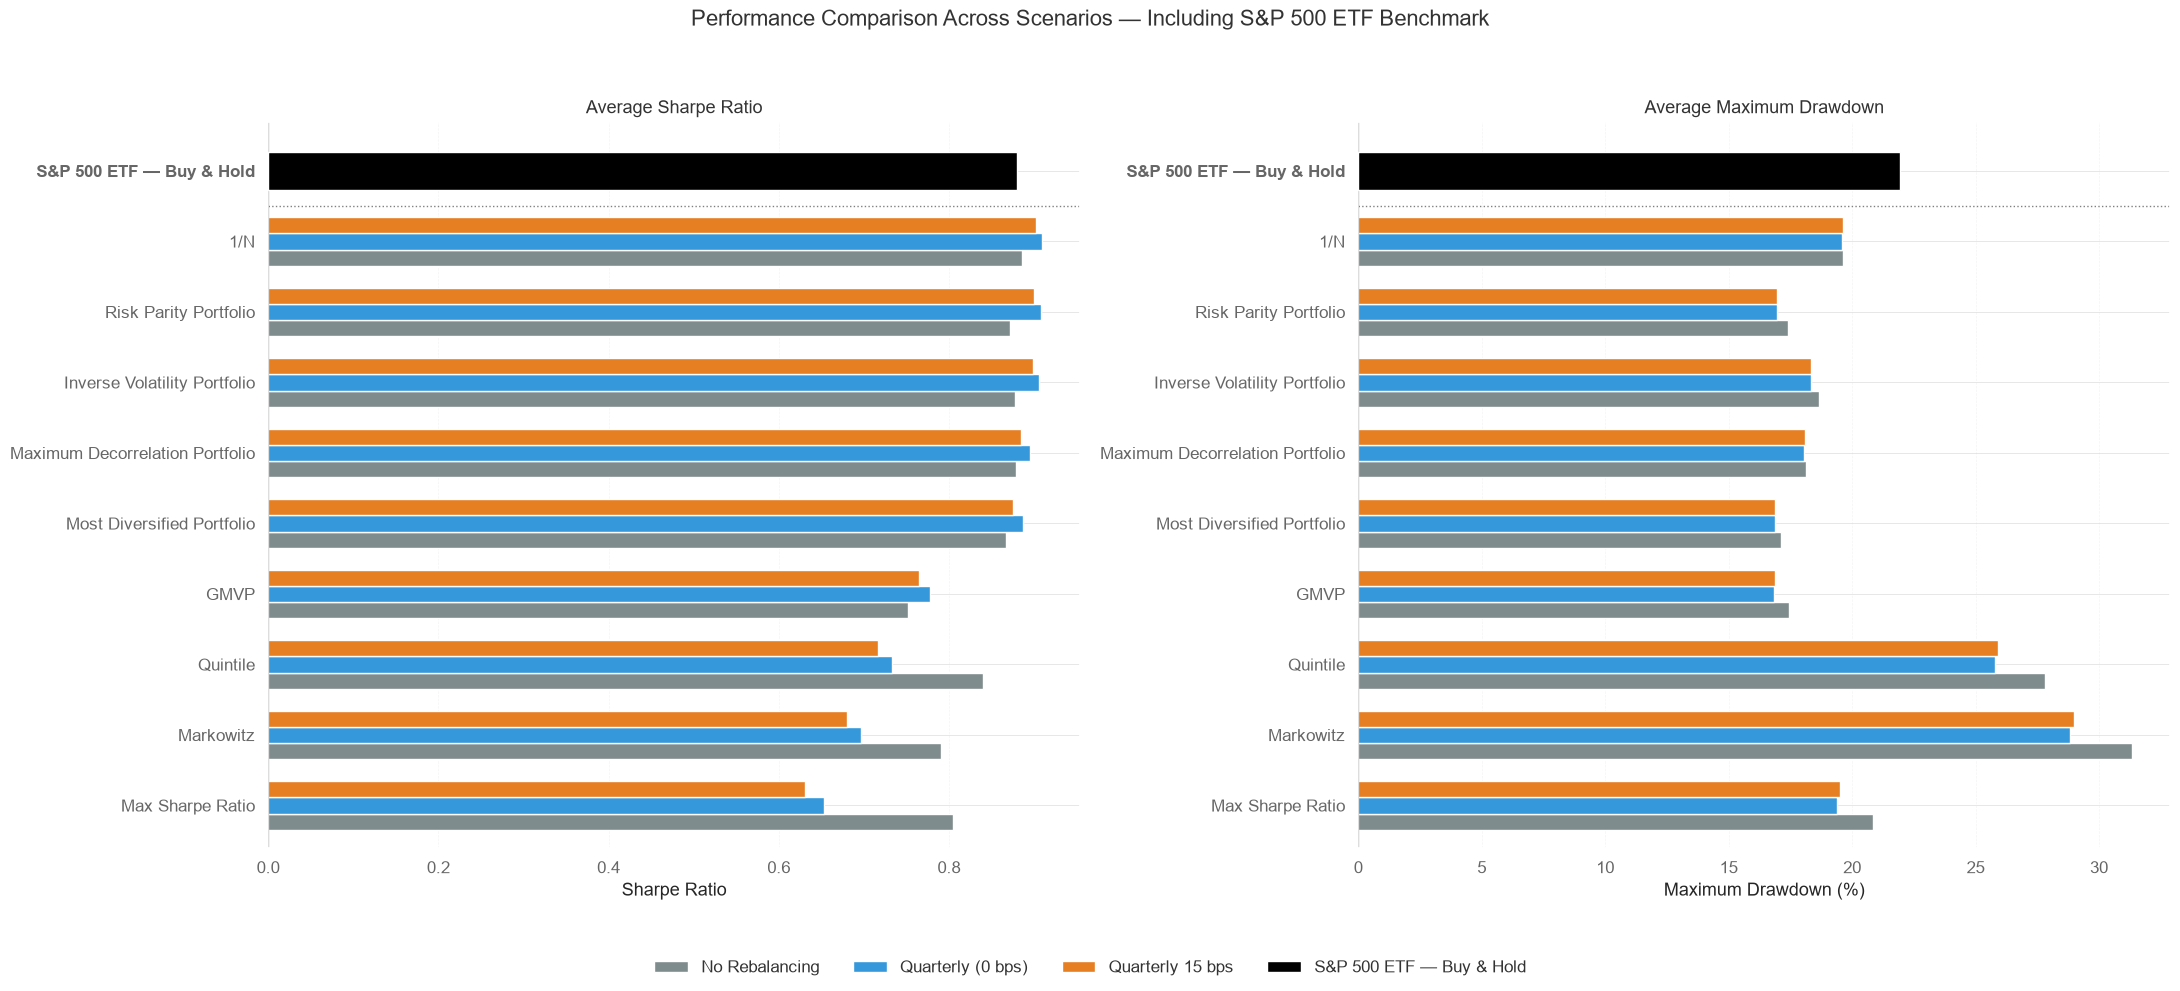

In [13]:
# ============================================================
# PREPARE COMPARISON TABLES
# ============================================================

fee_label = f"Quarterly {FEES * 10000:g} bps"
benchmark_label = "S&P 500 ETF — Buy & Hold"

sharpe_comparison = pd.DataFrame({
    "No Rebalancing": metrics_no_rebalancing["Sharpe Ratio"],
    "Quarterly (0 bps)": metrics_rebalancing_no_fees["Sharpe Ratio"],
    fee_label: metrics_rebalancing_with_fees["Sharpe Ratio"],
})

drawdown_comparison = pd.DataFrame({
    "No Rebalancing": metrics_no_rebalancing["Max Drawdown"],
    "Quarterly (0 bps)": metrics_rebalancing_no_fees["Max Drawdown"],
    fee_label: metrics_rebalancing_with_fees["Max Drawdown"],
})

# Same strategy order in both charts
strategy_order = sharpe_comparison.sort_values(
    fee_label,
    ascending=True,
).index

sharpe_comparison = sharpe_comparison.loc[strategy_order]
drawdown_comparison = drawdown_comparison.loc[strategy_order] * 100


# ============================================================
# PLOT
# ============================================================

fig, axes = plt.subplots(1, 2, figsize=(22, 10))

colors = ["#7F8C8D", "#3498DB", "#E67E22"]

# Position of each strategy and of the ETF benchmark
strategy_positions = np.arange(len(strategy_order))
benchmark_position = len(strategy_order)

bar_height = 0.23

chart_settings = [
    (
        sharpe_comparison,
        metrics_benchmark["Sharpe Ratio"],
        "Average Sharpe Ratio",
        "Sharpe Ratio",
    ),
    (
        drawdown_comparison,
        metrics_benchmark["Max Drawdown"] * 100,
        "Average Maximum Drawdown",
        "Maximum Drawdown (%)",
    ),
]

for ax, (table, benchmark_value, title, xlabel) in zip(
    axes,
    chart_settings,
):
    # Three separate bars per portfolio strategy
    for i, column in enumerate(table.columns):
        offset = (i - 1) * bar_height

        ax.barh(
            strategy_positions + offset,
            table[column].to_numpy(),
            height=bar_height,
            color=colors[i],
            label=column,
        )

    # One single bar for the ETF
    ax.barh(
        benchmark_position,
        benchmark_value,
        height=0.55,
        color="black",
        label=benchmark_label,
        zorder=3,
    )

    # Include the ETF in the labels and visible axis range
    ax.set_yticks(
        list(strategy_positions) + [benchmark_position]
    )
    ax.set_yticklabels(
        list(strategy_order) + [benchmark_label]
    )
    ax.set_ylim(-0.6, benchmark_position + 0.7)

    # Separate the ETF from the portfolio strategies
    ax.axhline(
        benchmark_position - 0.5,
        color="grey",
        linestyle=":",
        linewidth=1,
    )

    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel("")

    ax.axvline(0, color="black", linewidth=0.8)
    ax.grid(axis="x", linestyle="--", alpha=0.3)
    ax.set_axisbelow(True)

    # Highlight the ETF's axis label
    ax.get_yticklabels()[-1].set_fontweight("bold")


# Shared legend outside the charts
handles, labels = axes[0].get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    loc="lower center",
    ncol=4,
    frameon=False,
)

fig.suptitle(
    "Performance Comparison Across Scenarios — Including S&P 500 ETF Benchmark",
    fontsize=16,
)

plt.tight_layout(rect=[0, 0.07, 1, 0.95])
plt.show()

C:\Users\user\AppData\Local\Temp\ipykernel_2436\1764143066.py:80: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  boxes = ax.boxplot(
C:\Users\user\AppData\Local\Temp\ipykernel_2436\1764143066.py:80: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  boxes = ax.boxplot(
C:\Users\user\AppData\Local\Temp\ipykernel_2436\1764143066.py:80: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  boxes = ax.boxplot(


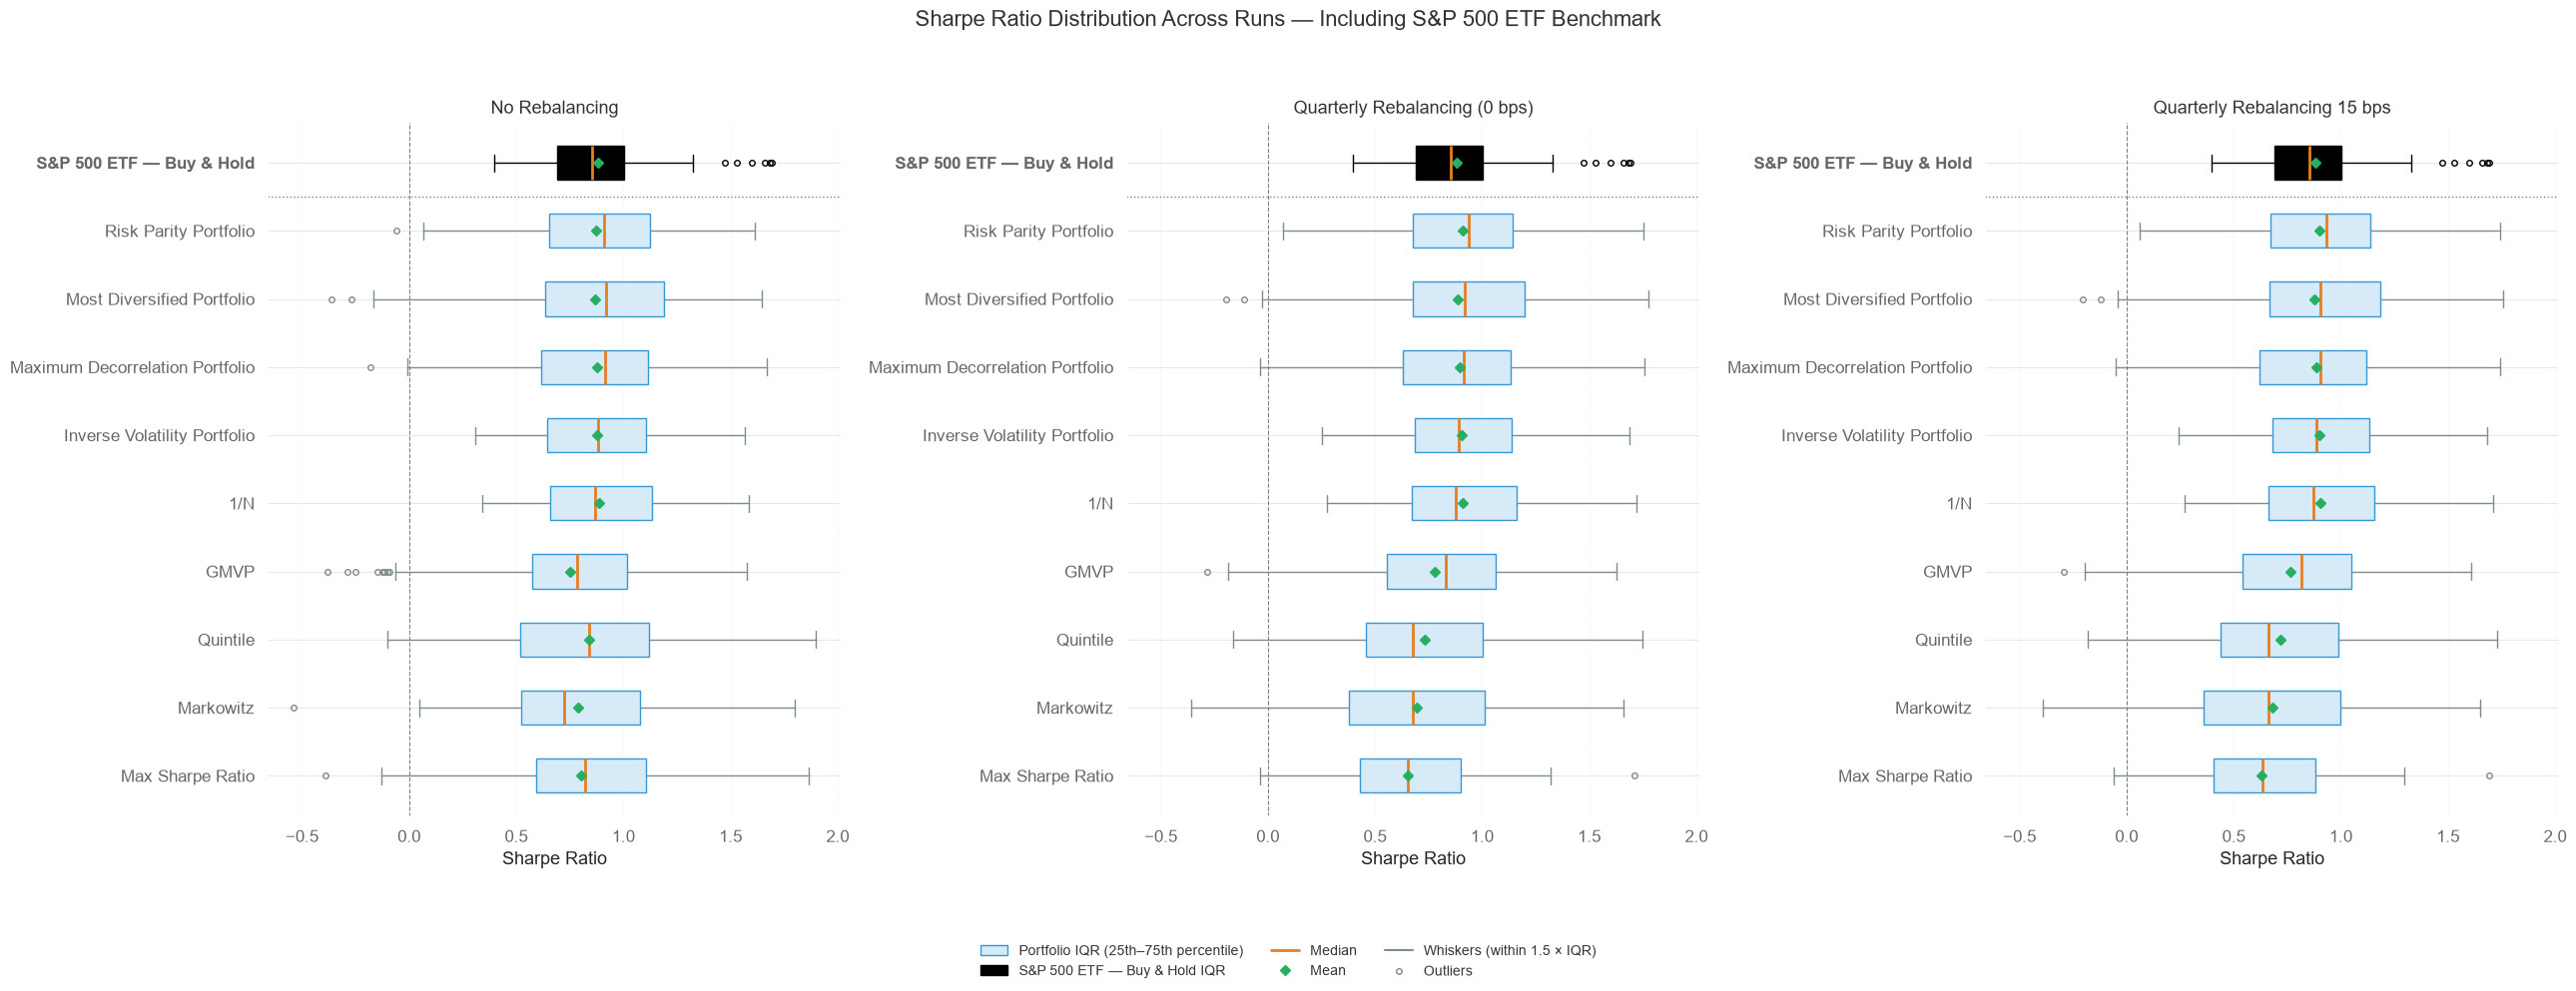

In [14]:
# ============================================================
# 1. SHARPE RATIOS BY RUN
# ============================================================

def sharpe_by_run(results_dict: dict) -> pd.DataFrame:
    return pd.DataFrame({
        strategy_name: [
            performance_metrics(run[0])["Sharpe Ratio"]
            for run in runs
        ]
        for strategy_name, runs in results_dict.items()
    })


sharpes_no_rebalancing = sharpe_by_run(
    results_no_rebalancing_fees
)

sharpes_rebalancing_no_fees = sharpe_by_run(
    results_rebalancing_no_fees
)

sharpes_rebalancing_with_fees = sharpe_by_run(
    results_rebalancing_fees
)


# ETF: calculate once and reuse in all three panels
benchmark_label = "S&P 500 ETF — Buy & Hold"

benchmark_sharpes = pd.Series([
    performance_metrics(returns, rf=rf)["Sharpe Ratio"]
    for returns in benchmark_runs
]).dropna().to_numpy()


# ============================================================
# 2. STRATEGY ORDER AND SCENARIOS
# ============================================================

strategy_order = (
    sharpes_rebalancing_with_fees
    .median()
    .sort_values()
    .index
)

scenarios = {
    "No Rebalancing": sharpes_no_rebalancing,
    "Quarterly Rebalancing (0 bps)": sharpes_rebalancing_no_fees,
    f"Quarterly Rebalancing {FEES * 10000:g} bps":
        sharpes_rebalancing_with_fees,
}

benchmark_position = len(strategy_order) + 1

positions = list(range(1, benchmark_position + 1))
labels = list(strategy_order) + [benchmark_label]


# ============================================================
# 3. PLOT
# ============================================================

fig, axes = plt.subplots(
    1, 3,
    figsize=(26, 10),
    sharex=True,
)

for ax, (scenario_name, sharpes) in zip(axes, scenarios.items()):
    values = [
        sharpes[strategy].dropna().to_numpy()
        for strategy in strategy_order
    ]

    # The same ETF distribution in every panel
    values.append(benchmark_sharpes)

    boxes = ax.boxplot(
        values,
        positions=positions,
        vert=False,
        patch_artist=True,
        showmeans=True,
        whis=1.5,
        boxprops={
            "facecolor": "#D6EAF8",
            "edgecolor": "#3498DB",
        },
        medianprops={
            "color": "#E67E22",
            "linewidth": 2,
        },
        meanprops={
            "marker": "D",
            "markerfacecolor": "#27AE60",
            "markeredgecolor": "#27AE60",
            "markersize": 5,
        },
        whiskerprops={"color": "#7F8C8D"},
        capprops={"color": "#7F8C8D"},
        flierprops={
            "marker": "o",
            "markerfacecolor": "none",
            "markeredgecolor": "#7F8C8D",
            "markersize": 4,
        },
    )

    # Highlight the ETF boxplot
    boxes["boxes"][-1].set_facecolor("black")
    boxes["boxes"][-1].set_edgecolor("black")

    for whisker in boxes["whiskers"][-2:]:
        whisker.set_color("black")

    for cap in boxes["caps"][-2:]:
        cap.set_color("black")

    boxes["fliers"][-1].set_markeredgecolor("black")

    ax.set_yticks(positions)
    ax.set_yticklabels(labels)
    ax.set_ylim(0.4, benchmark_position + 0.6)

    ax.get_yticklabels()[-1].set_fontweight("bold")

    # Separate the benchmark from the portfolio strategies
    ax.axhline(
        benchmark_position - 0.5,
        color="grey",
        linestyle=":",
        linewidth=1,
    )

    ax.set_title(scenario_name)
    ax.set_xlabel("Sharpe Ratio")
    ax.set_ylabel("")

    ax.axvline(
        0,
        color="grey",
        linestyle="--",
        linewidth=0.8,
    )

    ax.grid(axis="x", linestyle="--", alpha=0.3)
    ax.set_axisbelow(True)


# ============================================================
# 4. SHARED LEGEND
# ============================================================

legend_elements = [
    Patch(
        facecolor="#D6EAF8",
        edgecolor="#3498DB",
        label="Portfolio IQR (25th–75th percentile)",
    ),
    Patch(
        facecolor="black",
        edgecolor="black",
        label="S&P 500 ETF — Buy & Hold IQR",
    ),
    Line2D(
        [0], [0],
        color="#E67E22",
        linewidth=2,
        label="Median",
    ),
    Line2D(
        [0], [0],
        marker="D",
        color="none",
        markerfacecolor="#27AE60",
        markeredgecolor="#27AE60",
        markersize=5,
        label="Mean",
    ),
    Line2D(
        [0], [0],
        color="#7F8C8D",
        label="Whiskers (within 1.5 × IQR)",
    ),
    Line2D(
        [0], [0],
        marker="o",
        color="none",
        markerfacecolor="none",
        markeredgecolor="#7F8C8D",
        markersize=4,
        label="Outliers",
    ),
]

fig.legend(
    handles=legend_elements,
    loc="lower center",
    ncol=3,
    frameon=False,
    fontsize=10,
)

fig.suptitle(
    "Sharpe Ratio Distribution Across Runs — Including S&P 500 ETF Benchmark",
    fontsize=16,
)

plt.tight_layout(rect=[0, 0.10, 1, 0.95])

# Optional: save the figure
# fig.savefig(
#     documents_path / "sharpe_boxplots.png",
#     dpi=300,
#     bbox_inches="tight",
# )

plt.show()

**Conclusions**
<br>

**No Rebalancing**
<br>
**1)** The GMVP Strategy appears to have the highest presence of negative outliers in terms of Sharpe Ratio.

**2)** The Markowitz Strategy appears to have a number of positive outliers in terms of Sharpe Ratio.

**Rebalancing**
<br>
**1)** Once more, the GMVP Strategy appears to have the highest presence of negative outliers in terms of Sharpe Ratio.


## The following are just example graphs to better visualize returns on a given run

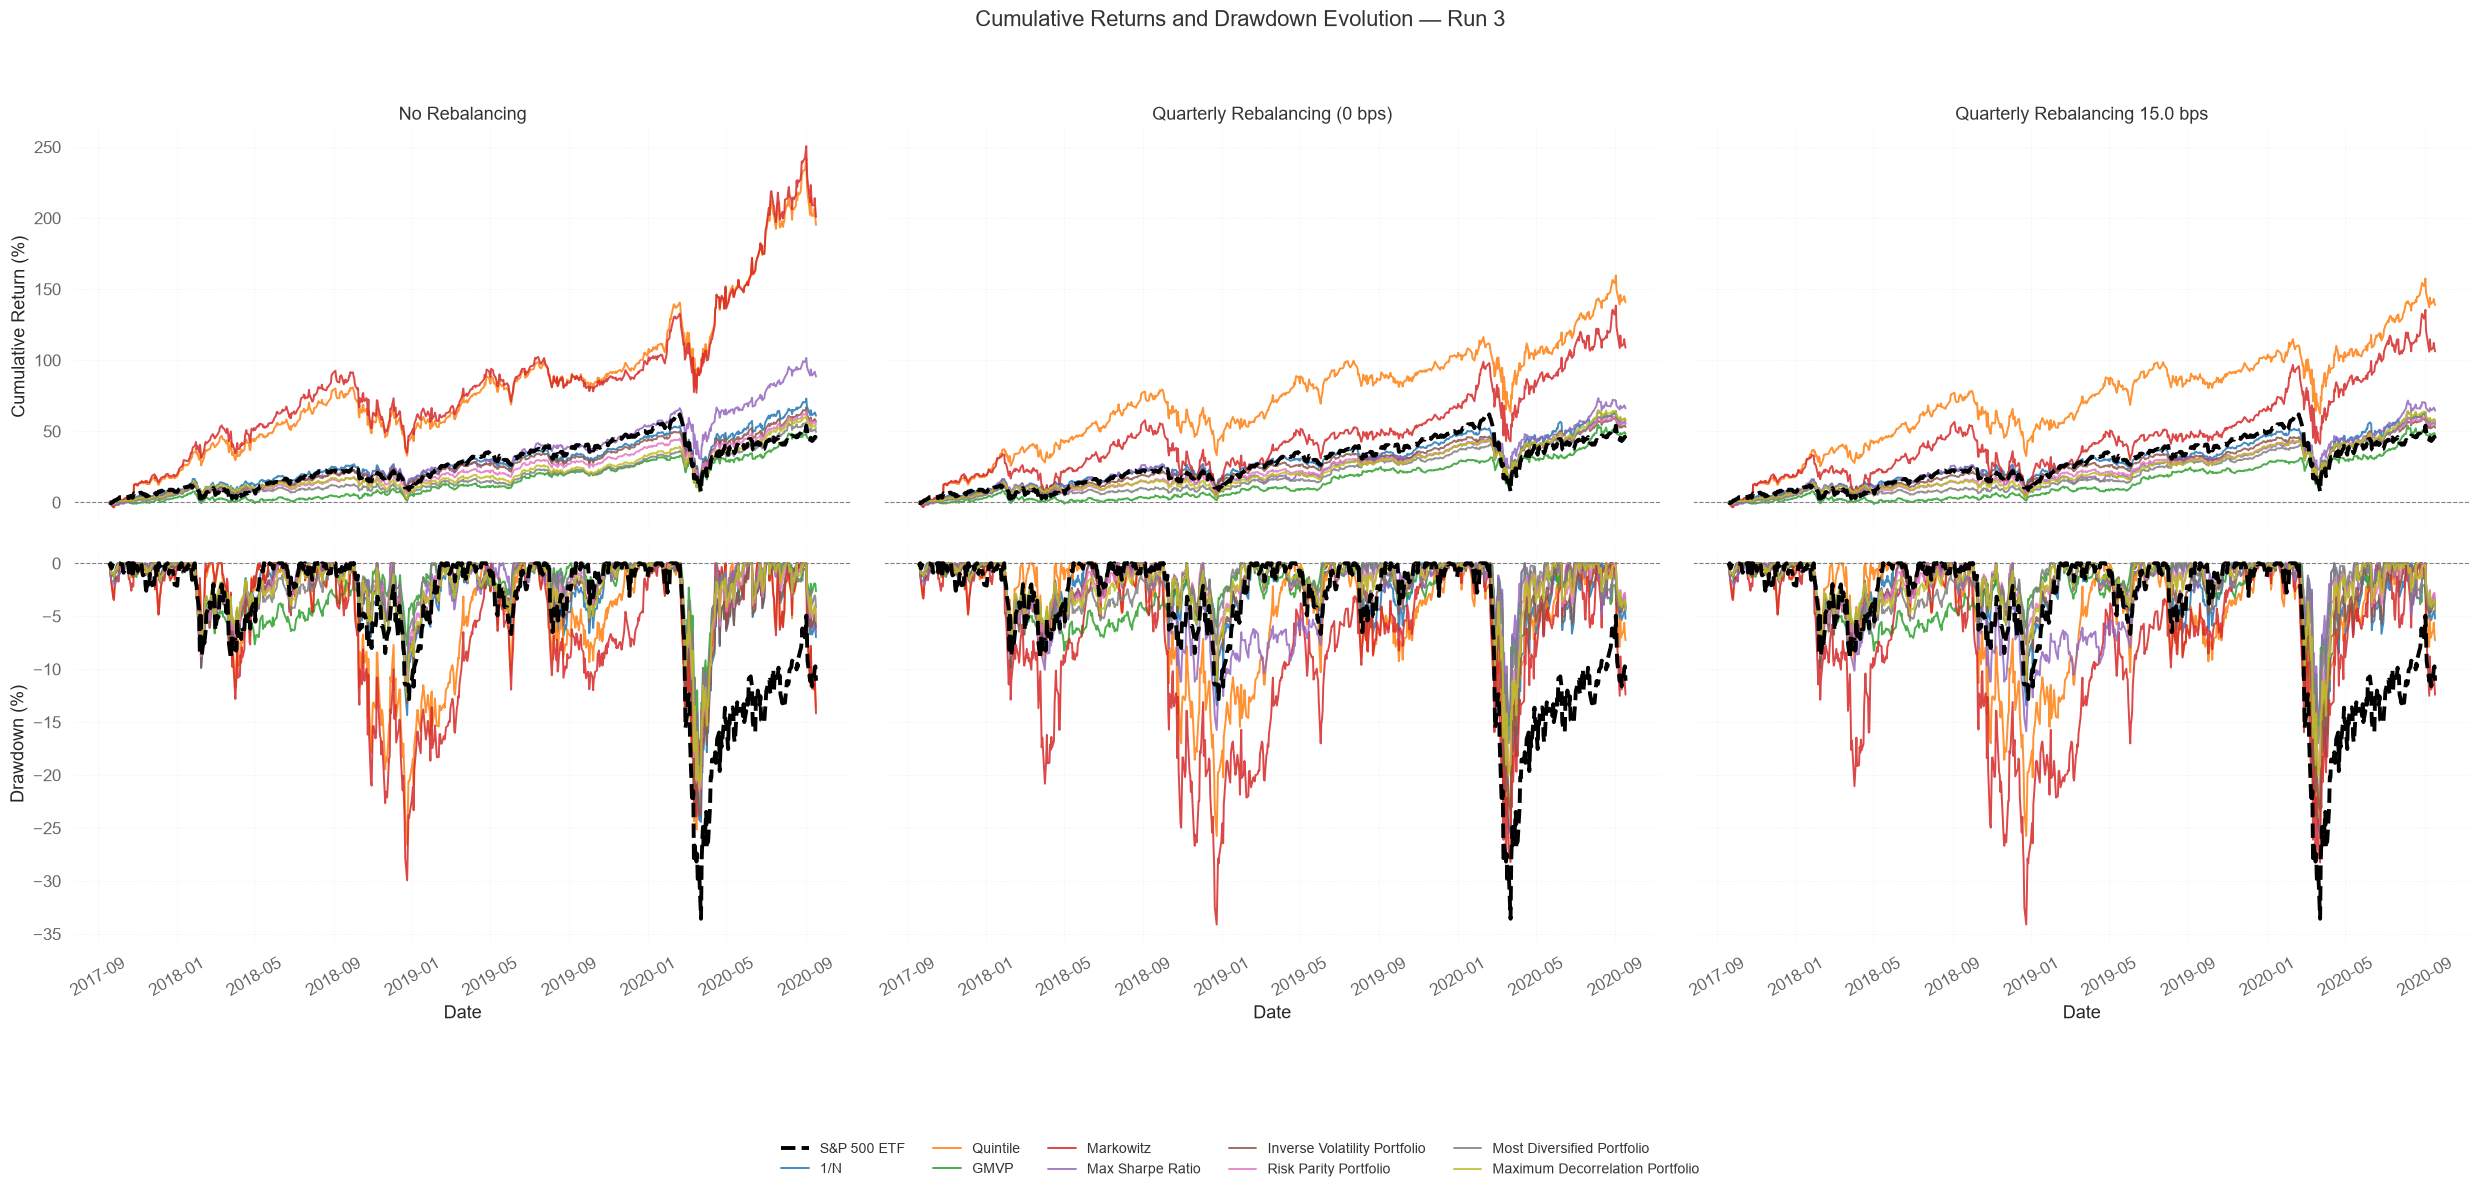

In [15]:
Run_Number = 3

scenarios = {
    "No Rebalancing": results_no_rebalancing_fees,
    "Quarterly Rebalancing (0 bps)": results_rebalancing_no_fees,
    f"Quarterly Rebalancing {round(FEES * 10000, 0)} bps": results_rebalancing_fees,
}

strategy_names = list(results_rebalancing_fees.keys())
colors = plt.get_cmap("tab10").colors

strategy_colors = {
    name: colors[i % len(colors)]
    for i, name in enumerate(strategy_names)
}

# Benchmark returns aligned to the selected run
benchmark_returns = prices_SP500.pct_change(fill_method=None)

first_strategy_returns = results_no_rebalancing_fees[
    strategy_names[0]
][Run_Number - 1][0]

benchmark_returns = benchmark_returns.reindex(
    first_strategy_returns.index
).fillna(0)

benchmark_cumulative_returns = (
    (1 + benchmark_returns).cumprod() - 1
) * 100

benchmark_drawdown = (
    (1 + benchmark_returns).cumprod()
    / (1 + benchmark_returns).cumprod().cummax()
    - 1
) * 100


fig, axes = plt.subplots(
    2, 3,
    figsize=(25, 12),
    sharex=True,
    sharey="row",
)

for column, (scenario_name, results_dict) in enumerate(scenarios.items()):
    returns = pd.DataFrame({
        name: runs[Run_Number - 1][0]
        for name, runs in results_dict.items()
    })

    wealth = (1 + returns).cumprod()
    cumulative_returns = (wealth - 1) * 100

    peak = wealth.cummax().clip(lower=1)
    drawdown = (wealth / peak - 1) * 100

    for name in strategy_names:
        axes[0, column].plot(
            cumulative_returns.index,
            cumulative_returns[name],
            color=strategy_colors[name],
            linewidth=1.4,
            alpha=0.85,
            label=name,
        )

        axes[1, column].plot(
            drawdown.index,
            drawdown[name],
            color=strategy_colors[name],
            linewidth=1.4,
            alpha=0.85,
            label=name,
        )

    # S&P 500 benchmark — highlighted
    axes[0, column].plot(
        benchmark_cumulative_returns.index,
        benchmark_cumulative_returns,
        color="black",
        linewidth=2.8,
        linestyle="--",
        label="S&P 500 ETF",
        zorder=10,
    )

    axes[1, column].plot(
        benchmark_drawdown.index,
        benchmark_drawdown,
        color="black",
        linewidth=2.8,
        linestyle="--",
        label="S&P 500 ETF",
        zorder=10,
    )

    axes[0, column].set_title(scenario_name)
    axes[1, column].set_xlabel("Date")

axes[0, 0].set_ylabel("Cumulative Return (%)")
axes[1, 0].set_ylabel("Drawdown (%)")

for ax in axes.flat:
    ax.axhline(0, color="grey", linestyle="--", linewidth=0.8)
    ax.grid(linestyle="--", alpha=0.3)
    ax.set_axisbelow(True)
    ax.tick_params(axis="x", labelrotation=30)

handles, labels = axes[0, 0].get_legend_handles_labels()

# Put the benchmark first in the legend
benchmark_index = labels.index("S&P 500 ETF")

handles = (
    [handles[benchmark_index]]
    + handles[:benchmark_index]
    + handles[benchmark_index + 1:]
)

labels = (
    [labels[benchmark_index]]
    + labels[:benchmark_index]
    + labels[benchmark_index + 1:]
)

fig.legend(
    handles,
    labels,
    loc="lower center",
    ncol=5,
    frameon=False,
    fontsize=10,
)

fig.suptitle(
    f"Cumulative Returns and Drawdown Evolution — Run {Run_Number}",
    fontsize=16,
)

plt.tight_layout(rect=[0, 0.12, 1, 0.95])

plt.show()

## Weight Evolution on a given run

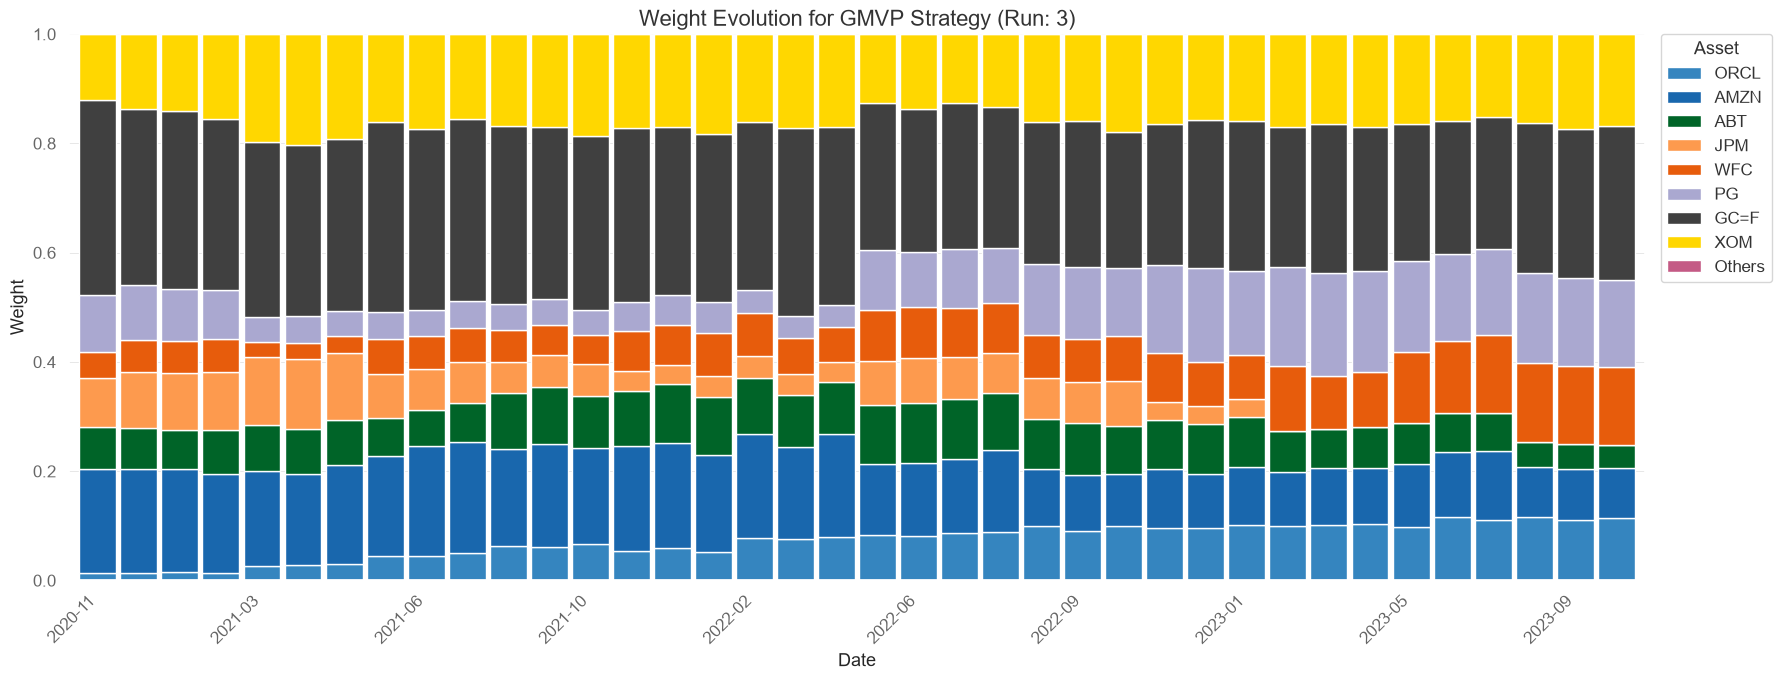

In [16]:
Run_Number=3
#To see the weight evolution of a given Strategy
#This is just to paint the same sectors with the same colours, just with different tones
sector_order = [
    "Technology",
    "Healthcare",
    "Financials",
    "Consumer Staples",
    "Commodities and Bonds",
    "Real Estate",
    "Energy",
]
asset_order = [
    asset
    for sector in sector_order
    for asset in groups[sector]
]

group_colors = {
    "Technology": "Blues",
    "Healthcare": "Greens",
    "Financials": "Oranges",
    "Consumer Staples": "Purples",
    "Commodities and Bonds": "YlOrBr",
    "Real Estate": "Reds",
    "Energy": "Greys",
}

colors = {}

for group, assets in groups.items():
    cmap = colormaps[group_colors[group]]
    shades = np.linspace(0.45, 0.9, len(assets))

    colors.update({
        asset: cmap(shade)
        for asset, shade in zip(assets, shades)
    })

colors.update({
    "GC=F": "#404040",
    "SI=F": "#808080",
    "TLT": "#B0B0B0",
})
colors["XOM"] = "gold"
colors["VNQ"] = "red"
colors["Others"] = "#C45A85"

returns, weights = backtest_with_drift(
    datasets[f"dataset {Run_Number-1}"], 
    maximum_decorrelation_portfolio, # <- Change the Strategy
    rebalance_every=int(21*3) , # <- Change the rebalancing period (if = len(datasets[f"dataset {Run_Number-1}"]) then there will be no rebalancing)
    return_weights=True
)

#Plot Creation 
#weights_plot = weights.iloc[::20] #This selects every line with a space of 20 per selection

weights_plot = weights.iloc[::20].copy()

threshold = 0.01

important = weights_plot.where(weights_plot >= threshold, 0)
others = weights_plot.where(weights_plot < threshold, 0).sum(axis=1)

asset_order = [
    asset
    for asset in asset_order
    if asset in important.columns
    and important[asset].max() > 0
]

weights_plot = important[asset_order].copy()
weights_plot["Others"] = others


fig, ax = plt.subplots(figsize=(18, 7))

weights_plot.plot.bar(
    stacked=True,
    ax=ax,
    width=0.9,
    color=[
        colors.get(asset, "lightgray")
        for asset in weights_plot.columns
    ]
)

ax.set_title(
    f"Weight Evolution for GMVP Strategy (Run: {Run_Number})",
    fontsize=16
)
ax.set_xlabel("Date")
ax.set_ylabel("Weight")
ax.set_ylim(0, 1)

ax.legend(
    title="Asset",
    bbox_to_anchor=(1.01, 1),
    loc="upper left",
    borderaxespad=0
)

ax.set_xticks(range(0, len(weights_plot), 4))
ax.set_xticklabels(
    weights_plot.index[::4].strftime("%Y-%m"),
    rotation=45,
    ha="right"
)

plt.tight_layout()
plt.show()